<a href="https://colab.research.google.com/github/AntikGhalt/dsge-ccnl-wage-indexation/blob/main/DSGE_run_save.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title 0. Mount Google Drive
from google.colab import drive
# Mount Google Drive to the /content/drive directory
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip -q install numpy scipy pandas matplotlib

In [ ]:
#@title inport
# ============================================================
# RUN PERSONALIZZATA DEL MODELLO
# ============================================================

from pathlib import Path
from dataclasses import asdict
from IPython.display import display, Image, Markdown
import importlib.util
import shutil
import pandas as pd

# Specifica economica del modello

,blocco,elemento,specifica,interpretazione
0,Baseline comune,Inflazione attesa,2.0% annuo,Gia' incorporata nelle tranche del sentiero ba...
1,Baseline comune,Floor nominale,Salario nominale non puo' diminuire,La deviazione puo' essere negativa finche' bas...
2,Scala mobile style,Indicizzazione,Ogni mese,Headline realizzata; intera retribuzione; barg...
3,Annuale NEI,Indicizzazione,Tutti a giugno,Minimo: recupera l'IPCA-NEI dell'anno solare p...
4,Tradizionale 36m,Inflazione prevista,Tranche nel baseline,La previsione fatta al contratto e' gia' nel s...
5,Tradizionale 36m,Errore inflazione,Recuperato al rinnovo,Solo la sorpresa rispetto alla previsione prec...
6,Tradizionale 36m,Previsione futura dopo lo shock,Nuovo contratto,Al rinnovo usa il sentiero futuro atteso/RE de...
7,Tutti i regimi,Bargaining,Ogni 36 mesi,Orologio separato dall'indicizzazione; default...
8,Tutti i regimi,Salari individuali,Continuamente,Wage drift/superminimi/promozioni possono muov...
9,Shock energia,Headline,Immediato,L'energia importata entra direttamente nell'in...


# Parametri e significato economico

,parameter,start,sensitivity_range,role,direction_if_higher,economic_element
0,beta_q,0.996512,0.985-0.999,Discount factor,↑ piu' forward-looking,Fattore di sconto intertemporale
1,sigma,1.0,0.5-3,CRRA / 1-IES,↑ consumo meno elastico,CRRA = Constant Relative Risk Aversion; IES = ...
2,habit_m,0.35,0-0.8,Habit mensile,↑ c e y piu' persistenti,Habit formation = consumo corrente dipende dal...
3,omega_q,0.75,0.5-0.9,Calvo pricing,↑ prezzi piu' rigidi,Calvo = probabilita' di non poter riottimizzar...
4,phi_pi,2.0,1.2-3,Taylor rule,↑ risposta monetaria piu' aggressiva,Reazione del tasso nominale all'inflazione
5,rho_cost_m,0.55,0-0.95,Cost-push,↑ shock piu' persistente,AR(1) mensile; half-life ≈ 1.2 mesi
6,rho_energy_m,0.75,0-0.98,Energia importata,↑ shock piu' persistente,AR(1) mensile; half-life ≈ 2.4 mesi
7,energy_weight_headline,0.1,0.05-0.20,Energia -> headline,↑ impatto diretto,Componente importata diretta nell'inflazione c...
8,energy_core_loading,0.08,0.02-0.20,Energia -> core,↑ maggiore pass-through,Quanto lo shock energia alimenta con ritardo x...
9,rho_energy_core_m,0.85,0.5-0.98,Persistenza pass-through,↑ contaminazione core piu' lenta/persistente,Persistenza della pressione energetica indiret...


# Equazioni principali

,eq,name,equation,interpretation
0,1,Euler,"lambda_t = E lambda_t+1 + i_t - E pi_headline,t+1",Domanda intertemporale
1,2,NKPC-NEI,pi_nei = beta E pi_nei+1 + kappa mc + zcost + ...,Core inflation / IPCA-NEI stilizzato
2,3,Headline,pi_headline = pi_nei + omega_E zenergy,Componente energetica diretta
3,4,Energy core pass-through,xE_t = rho_x xE_t-1 + lambda_E zenergy_t-1,Energia contamina il core con ritardo
4,5,Marginal cost,mc = weff_r - mpl,Il costo usa il salario effettivo
5,6,Employment,n_t=(1-s)n_t-1+s*m_t,Stock occupati
6,7,Participation,lfp_t=rho_L lfp_t-1+chi_w weff_r+chi_y y,Partecipazione separata
7,8,Unemployment,U=L-N,Disoccupazione stock
8,9,Matching,m=xi v+(1-xi)searchers,Nuovi match
9,10,Taylor,i=rho_i i(-1)+(1-rho_i)(phi_pi*pi+phi_y*y)-ur,Politica monetaria


# Esperimento: `institutional`

Solvo  institutional | shock= cost_push |            mobile_1m | basis=headline | scope=full
Solvo  institutional | shock= cost_push |       annual_nei_12m | basis=     nei | scope=minimum
Solvo  institutional | shock= cost_push |      traditional_36m | basis=     nei | scope=minimum
Solvo  institutional | shock=    energy |            mobile_1m | basis=headline | scope=full
Solvo  institutional | shock=    energy |       annual_nei_12m | basis=     nei | scope=minimum
Solvo  institutional | shock=    energy |      traditional_36m | basis=     nei | scope=minimum
Solvo  institutional | shock=technology |            mobile_1m | basis=headline | scope=full
Solvo  institutional | shock=technology |       annual_nei_12m | basis=     nei | scope=minimum
Solvo  institutional | shock=technology |      traditional_36m | basis=     nei | scope=minimum


# ccnl_indexation_irf_institutional_costpush

## pi_headline

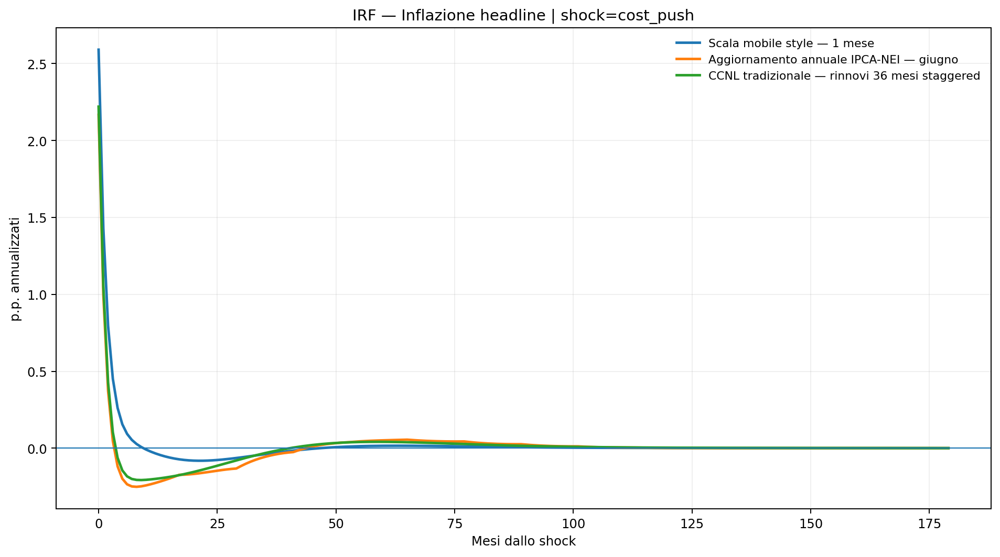

**Come leggere la variabile:** Inflazione complessiva. Nello shock energia reagisce subito alla componente importata e poi anche al pass-through core.

## pi_nei

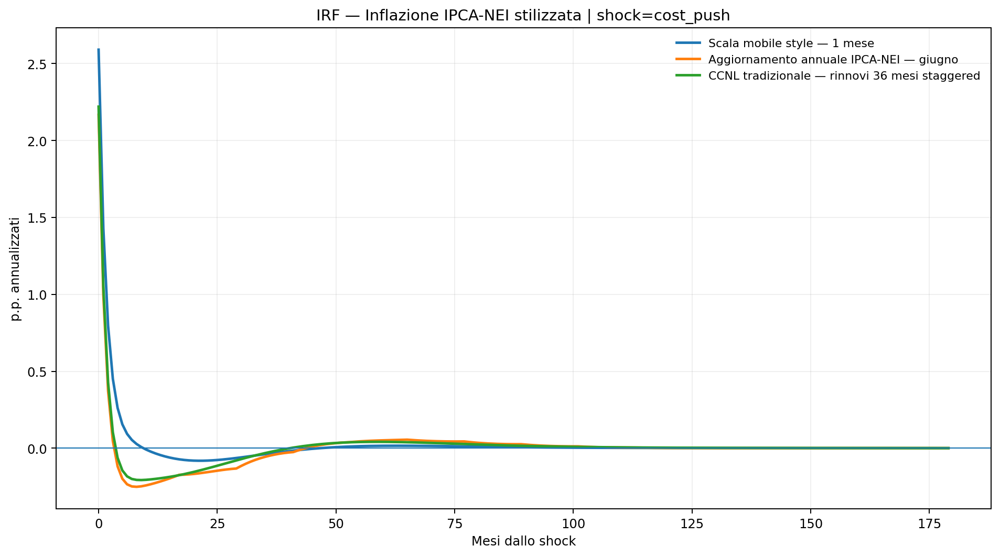

**Come leggere la variabile:** Esclude l'energia importata diretta. Lo shock energia entra solo con ritardo tramite xenergy_core.

## xenergy_core

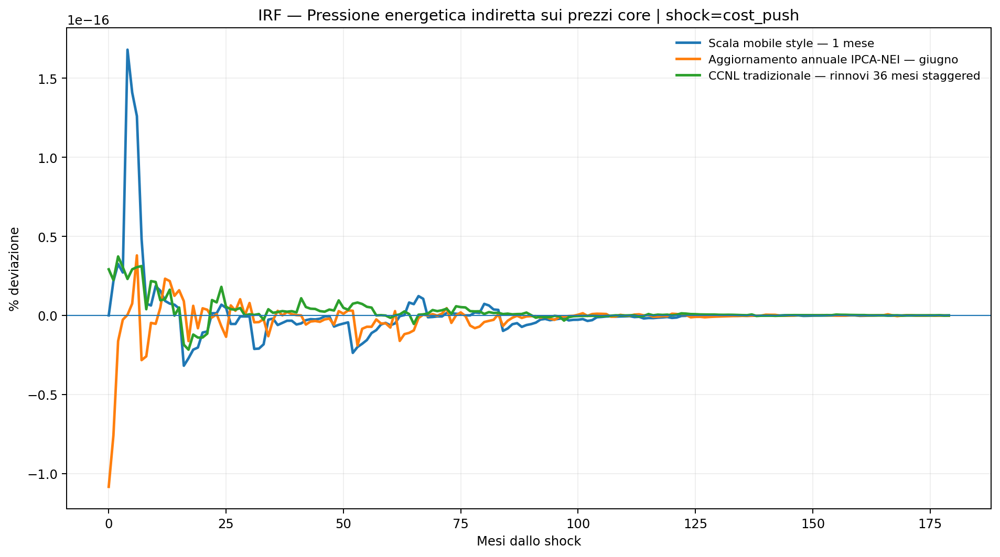

**Come leggere la variabile:** Stato che accumula gradualmente il pass-through dell'energia su input, trasporti, servizi e altri prezzi inclusi nel NEI.

## wpi_contract

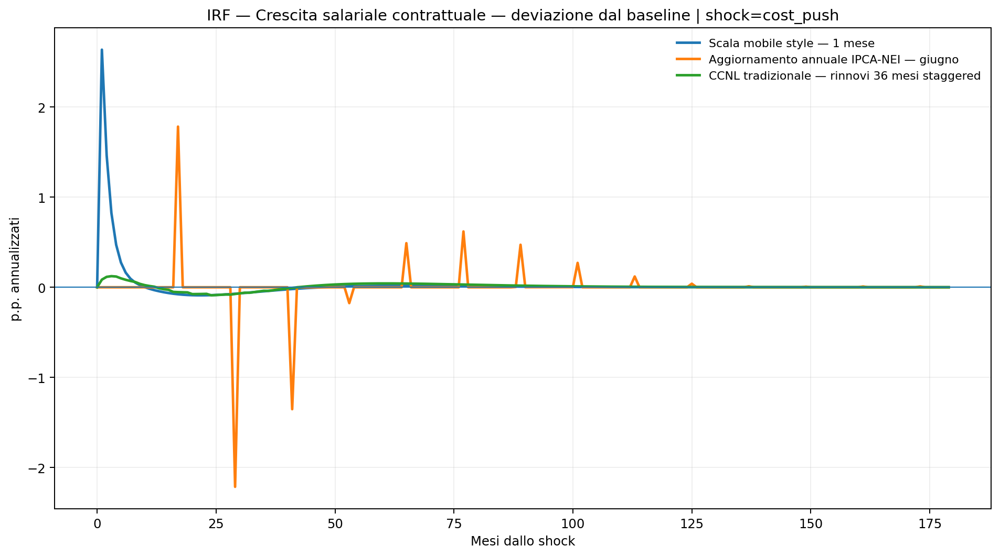

**Come leggere la variabile:** Deviazione dagli aumenti gia' previsti nel contratto. Nel tradizionale le tranche sull'inflazione prevista di base sono gia' nel baseline.

## wpi_indexation

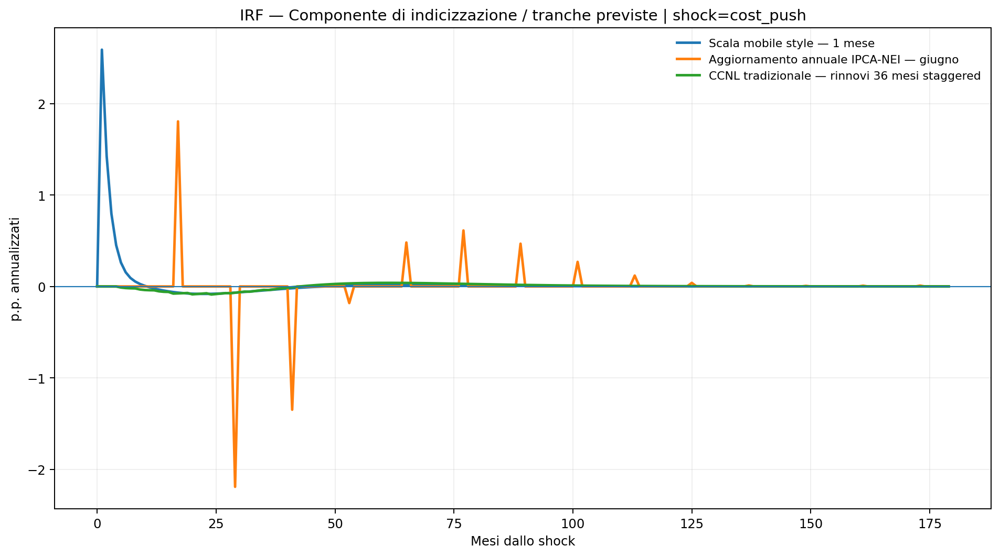

**Come leggere la variabile:** Mobile: headline mensile; annuale: NEI anno precedente a giugno; tradizionale: nuove tranche sulla previsione futura condizionata allo shock.

## wpi_catchup

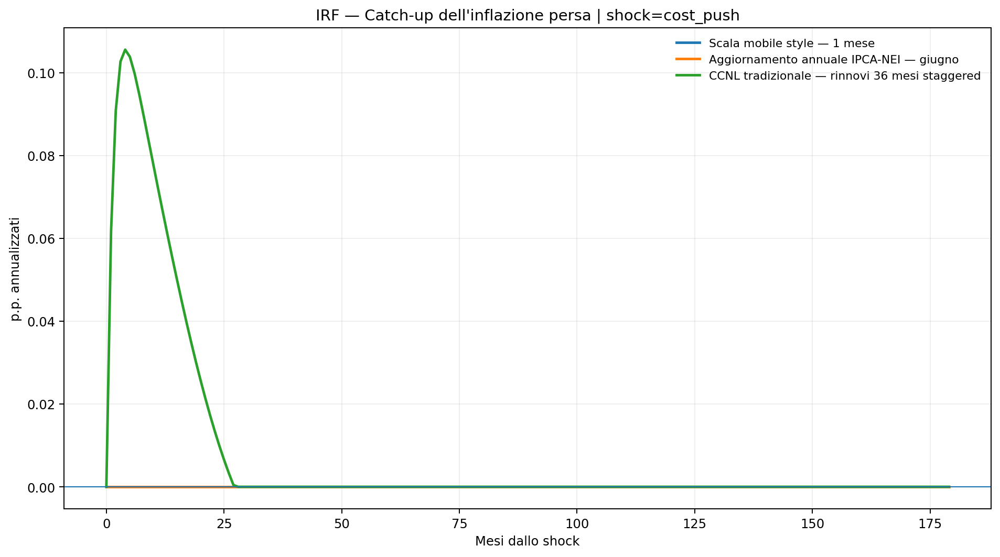

**Come leggere la variabile:** Recupero dell'errore positivo di inflazione non gia' compensato. Nel regime tradizionale avviene al rinnovo triennale staggered.

## wpi_bargaining

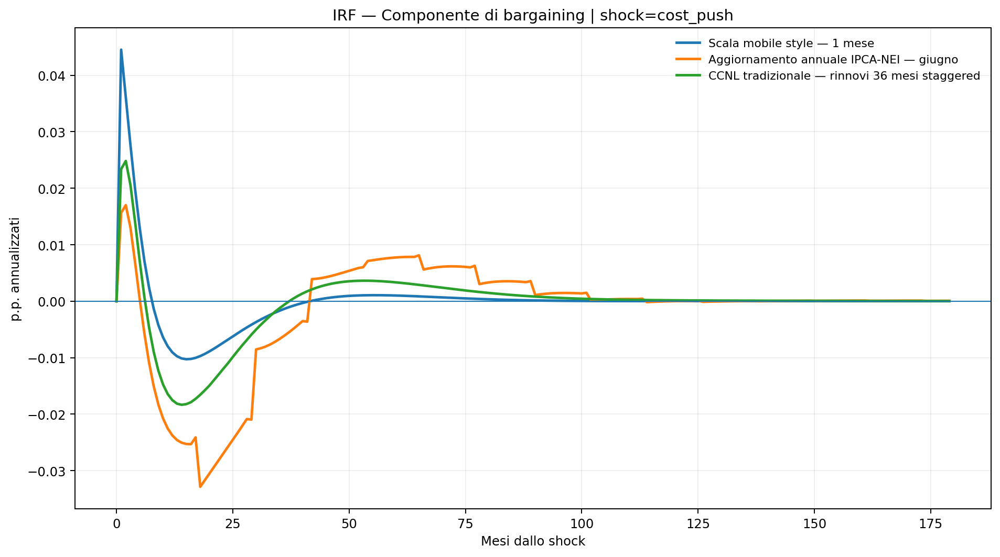

**Come leggere la variabile:** Aggiustamento reale verso il benchmark Nash. Ha sempre orologio separato di 36 mesi.

## wpi_drift

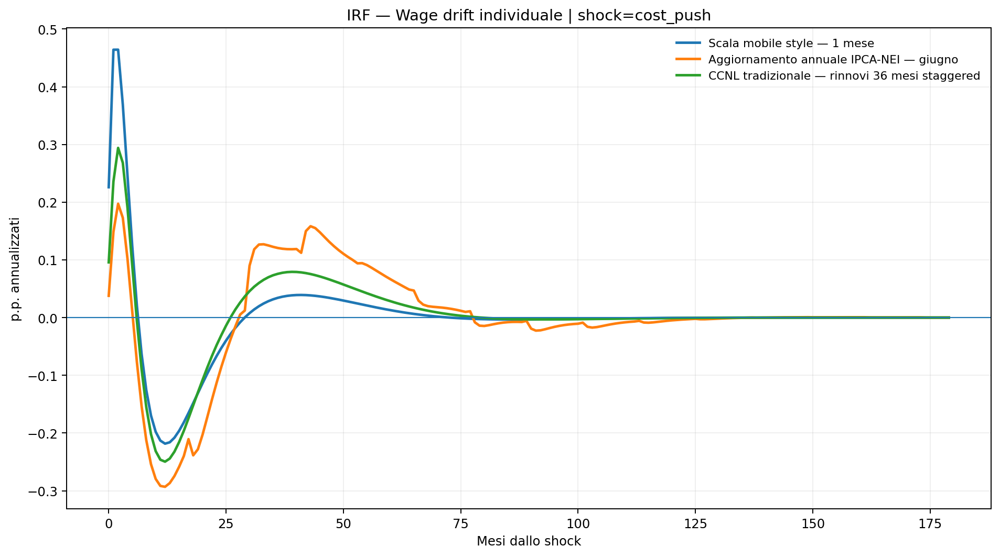

**Come leggere la variabile:** Superminimi, promozioni e aggiustamenti individuali: possono muoversi anche quando il minimo non viene aggiornato.

## wpi_eff

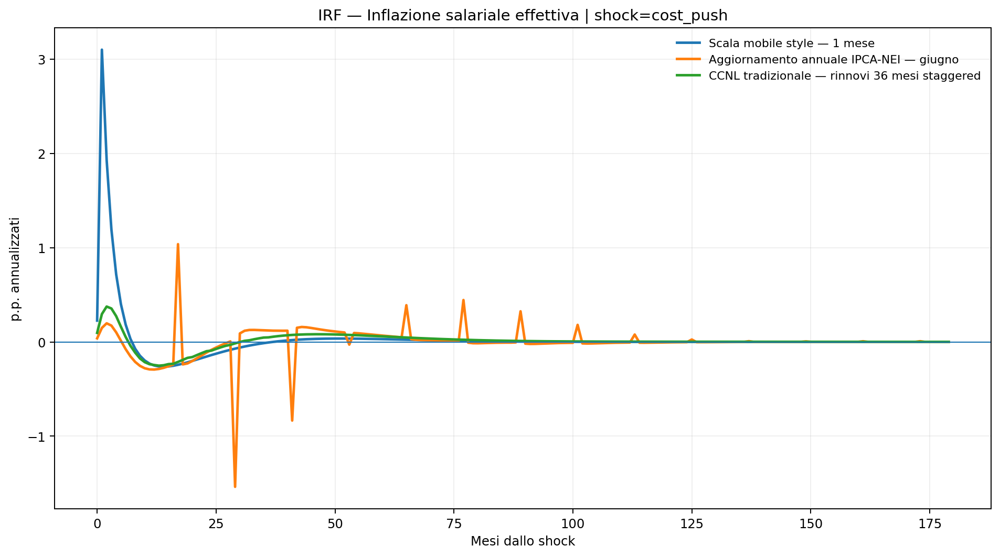

**Come leggere la variabile:** Somma della componente contrattuale trasmessa all'effettivo e del wage drift individuale.

## wmin_r

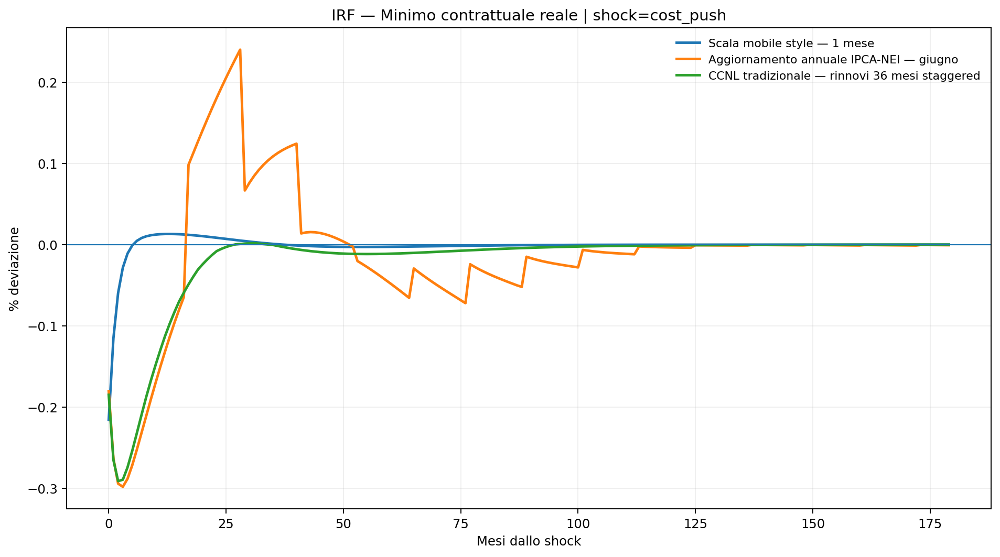

**Come leggere la variabile:** Potere d'acquisto del minimo rispetto al baseline contrattuale.

## weff_r

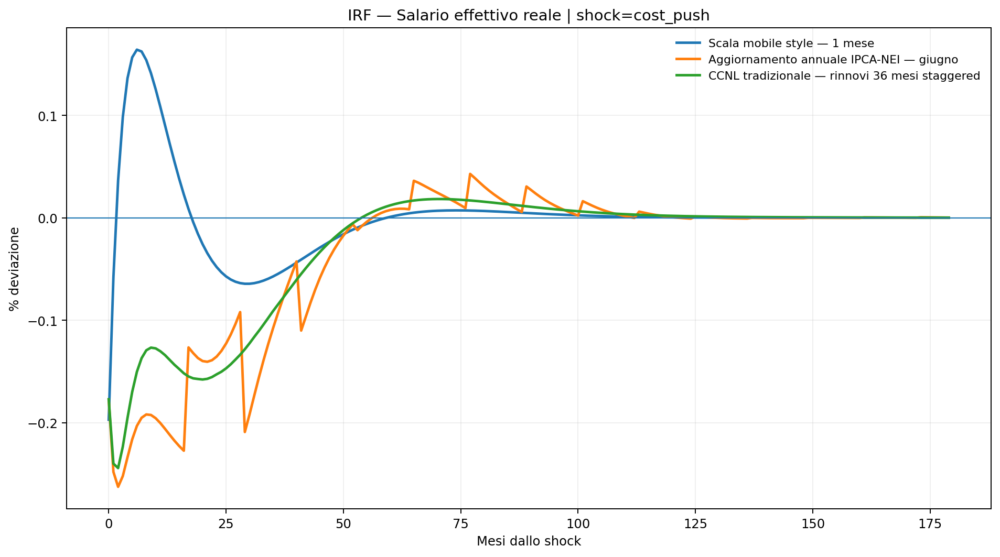

**Come leggere la variabile:** Retribuzione effettivamente pagata; e' questa, non il solo minimo, che entra nel costo marginale.

## wage_gap

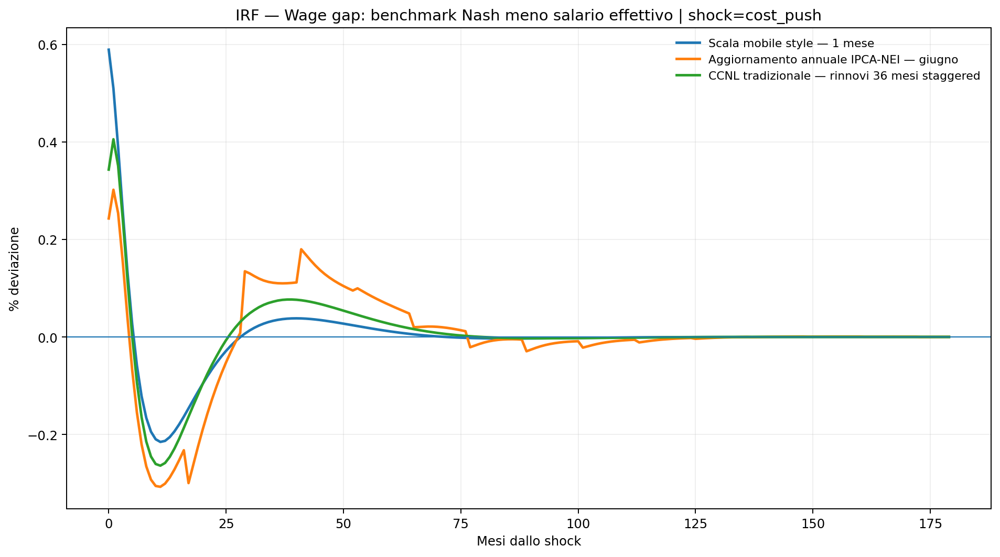

**Come leggere la variabile:** Positivo = salario effettivo sotto il benchmark; alimenta wage drift e bargaining.

## mc

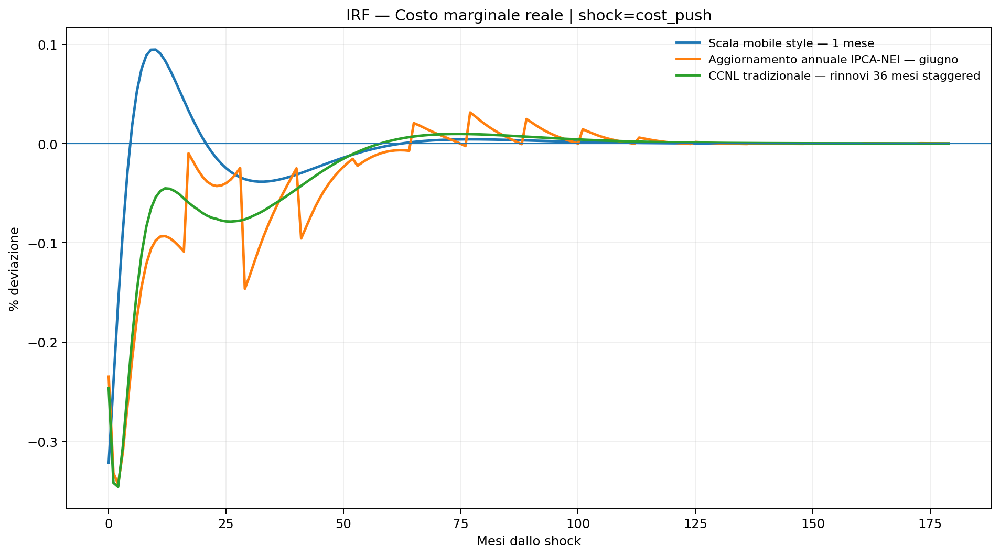

**Come leggere la variabile:** Ponte tra salario effettivo, produttivita' e inflazione NEI.

## i

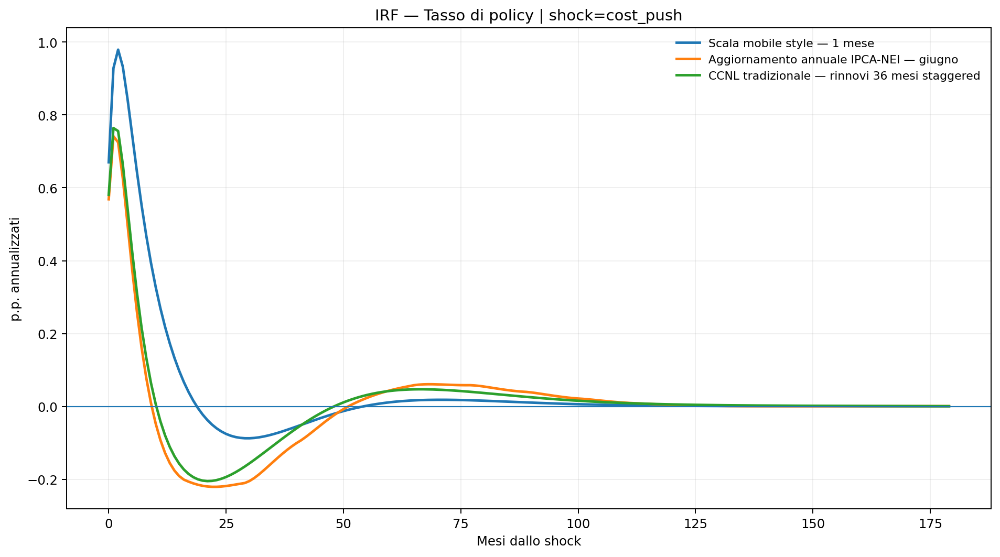

**Come leggere la variabile:** Risposta della banca centrale a inflazione e output.

## y

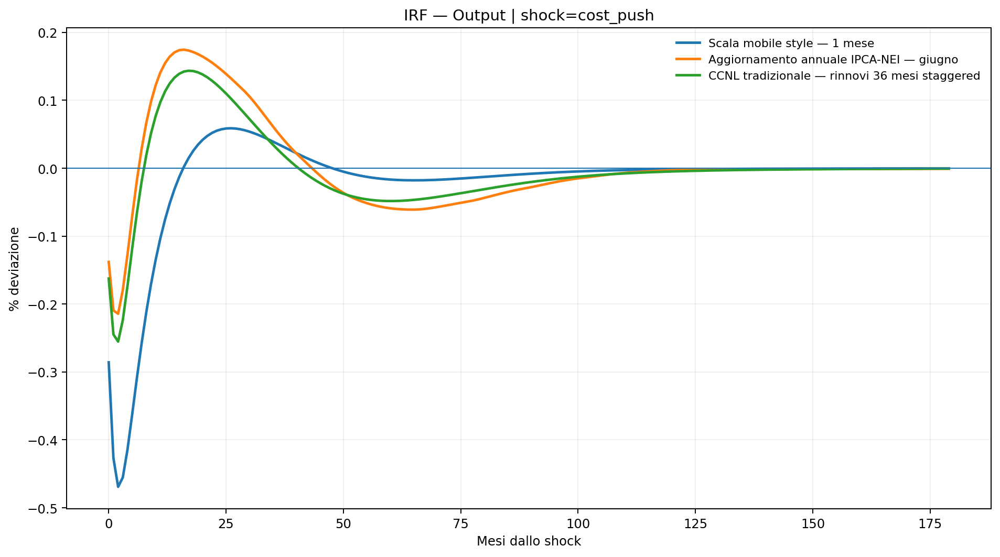

**Come leggere la variabile:** Produzione rispetto al sentiero di base.

## n

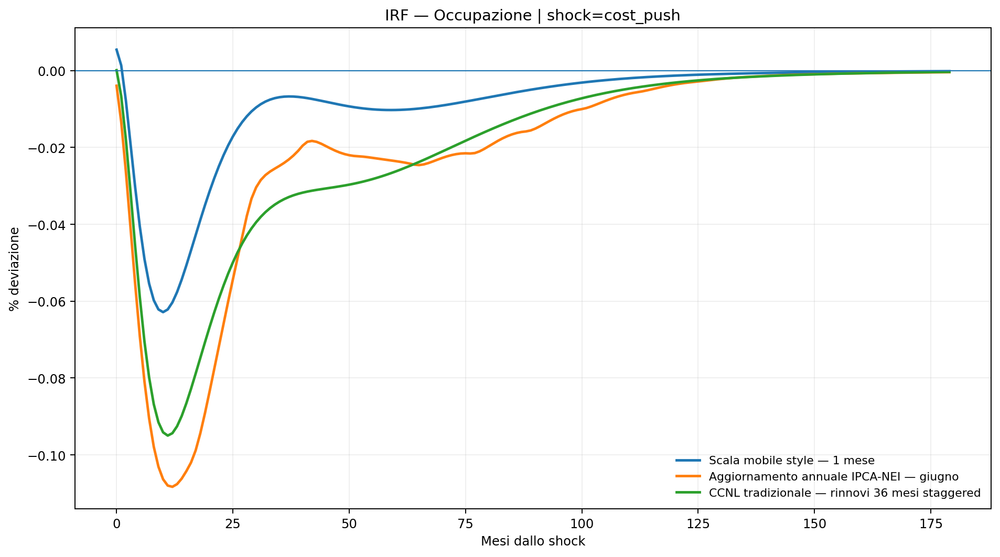

**Come leggere la variabile:** Stock di occupati generato da separazioni e nuovi match.

## u

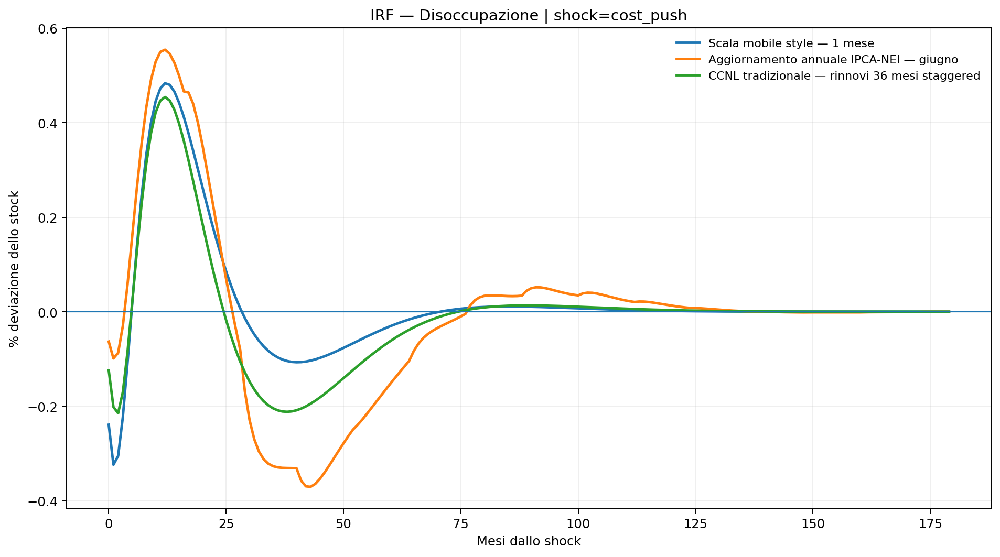

**Come leggere la variabile:** Stock U=L-N. Non leggere l'asse come punti percentuali del tasso ISTAT.

## lfp

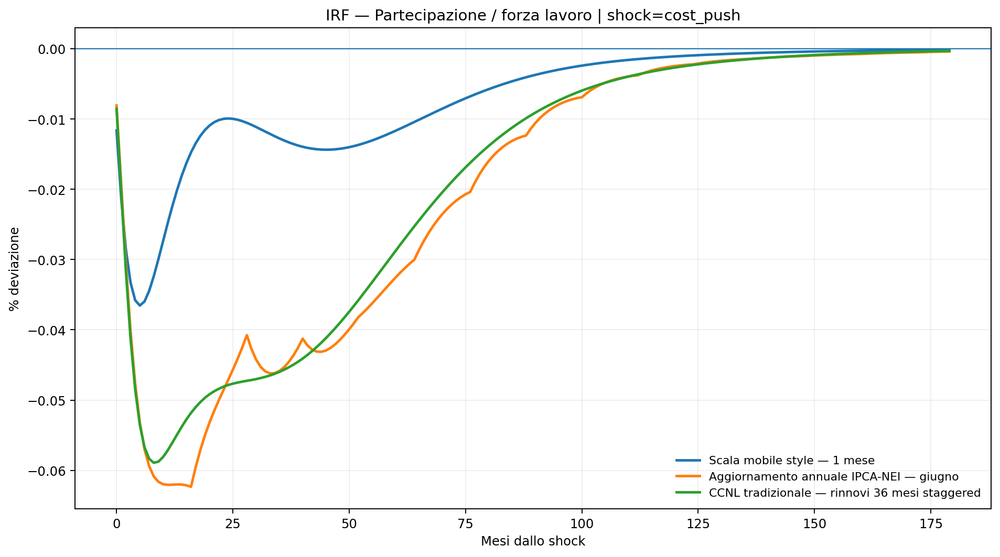

**Come leggere la variabile:** Entrata/uscita dalla forza lavoro in risposta a ciclo e salario reale.

## v

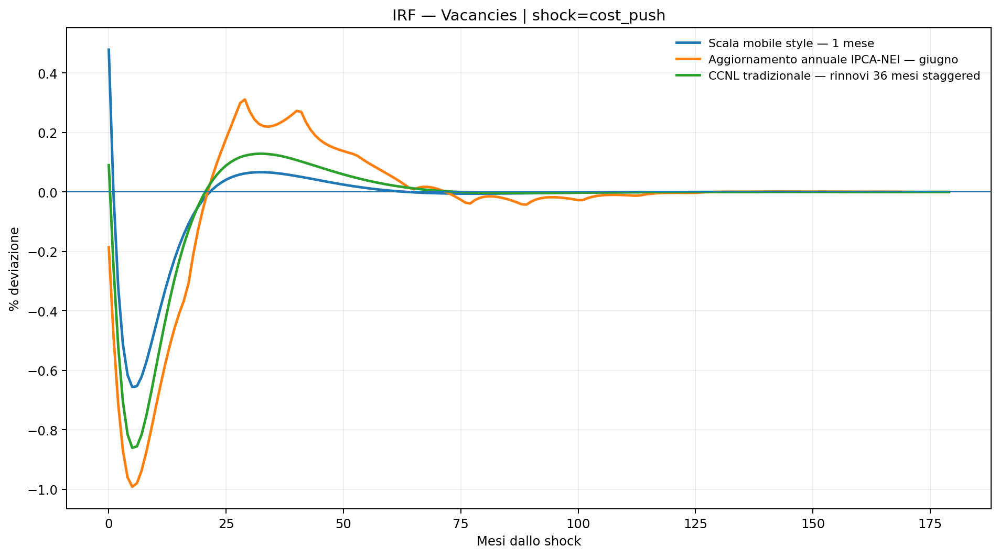

**Come leggere la variabile:** Domanda di lavoro delle imprese; utile per diagnosticare surplus eccessivi da salari reali bassi.

## theta

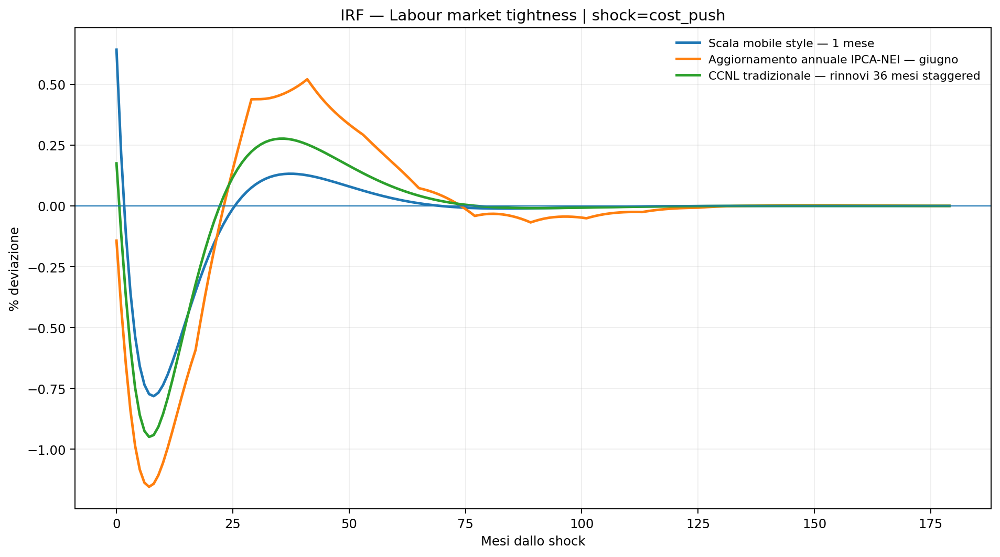

**Come leggere la variabile:** Vacancies relative ai searchers.

## price_level_headline

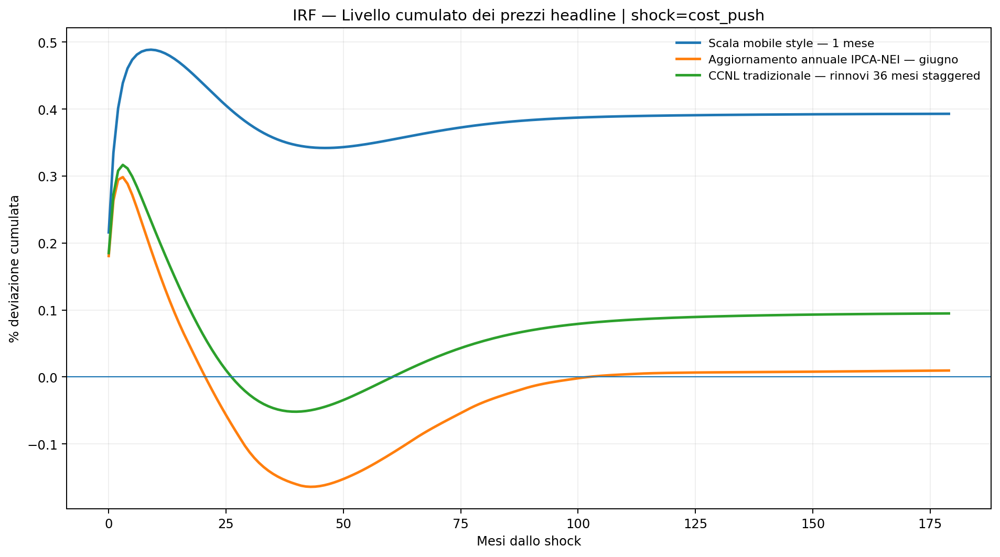

**Come leggere la variabile:** Somma dell'inflazione headline: mostra il livello dei prezzi, non solo il tasso.

## price_level_nei

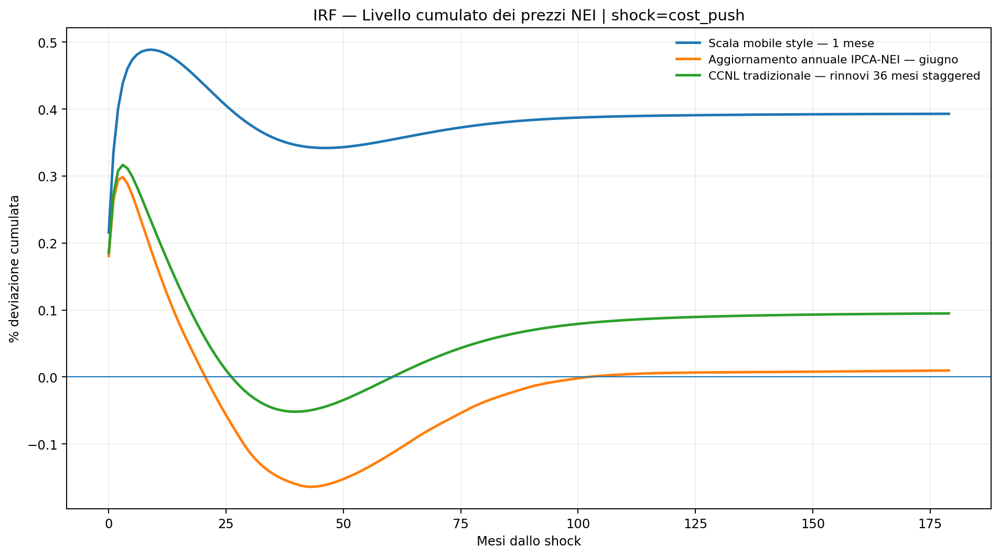

**Come leggere la variabile:** Livello cumulato della componente NEI/core.

## contract_wage_level

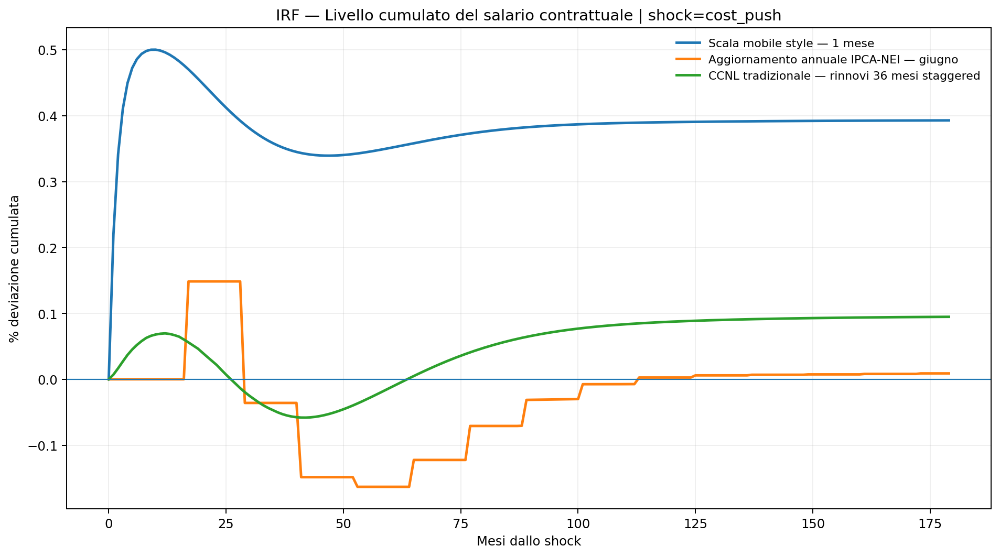

**Come leggere la variabile:** Deviazione cumulata rispetto al sentiero salariale contrattuale gia' programmato nel baseline.

## effective_wage_level

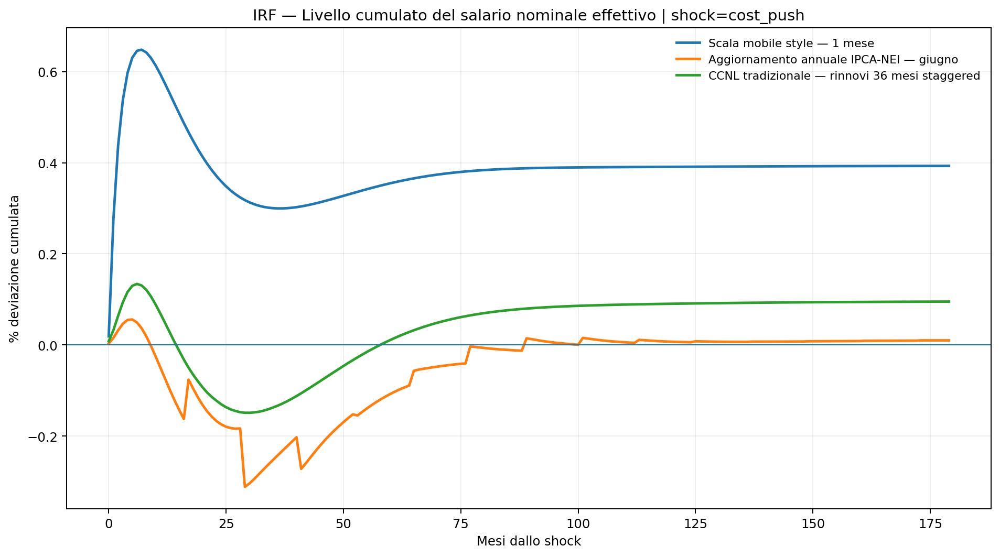

**Come leggere la variabile:** Include CCNL e wage drift; confrontalo con il livello dei prezzi.

## Sintesi numerica delle IRF

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_headline,2.590208,2.590208,0,5.0,0.392872,True
1,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_nei,2.590208,2.590208,0,5.0,0.392872,True
2,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_contract,-0.000000,2.634727,1,6.0,NaN,True
3,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_eff,0.225924,3.098899,1,6.0,NaN,True
4,mobile_1m,Scala mobile style — 1 mese,1,headline,full,weff_r,-0.197024,-0.197024,0,49.0,NaN,True
5,mobile_1m,Scala mobile style — 1 mese,1,headline,full,mc,-0.321839,-0.321839,0,40.0,NaN,True
6,mobile_1m,Scala mobile style — 1 mese,1,headline,full,y,-0.285805,-0.469093,2,33.0,NaN,True
7,mobile_1m,Scala mobile style — 1 mese,1,headline,full,n,0.005430,-0.062857,10,83.0,NaN,True
8,mobile_1m,Scala mobile style — 1 mese,1,headline,full,u,-0.239050,0.483668,12,56.0,NaN,True
9,mobile_1m,Scala mobile style — 1 mese,1,headline,full,v,0.478397,-0.656178,5,19.0,NaN,True


## Benchmark diagnostico: nessuna indicizzazione automatica

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_headline,2.113745,2.113745,0,20.0,-0.082761,True
1,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_nei,2.113745,2.113745,0,20.0,-0.082761,True
2,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_contract,-0.000000,-0.030831,14,65.0,NaN,True
3,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_eff,-0.023953,-0.350730,11,75.0,NaN,True
4,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,weff_r,-0.178142,-0.269355,2,48.0,NaN,True
5,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,mc,-0.221875,-0.326658,2,45.0,NaN,True
6,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,y,-0.110211,0.224867,15,97.0,NaN,True
7,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,n,-0.008166,-0.107877,11,86.0,NaN,True
8,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,u,0.000687,0.616467,11,80.0,NaN,True
9,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,v,-0.473726,-1.074263,5,57.0,NaN,True


# ccnl_indexation_irf_institutional_energy

## pi_headline

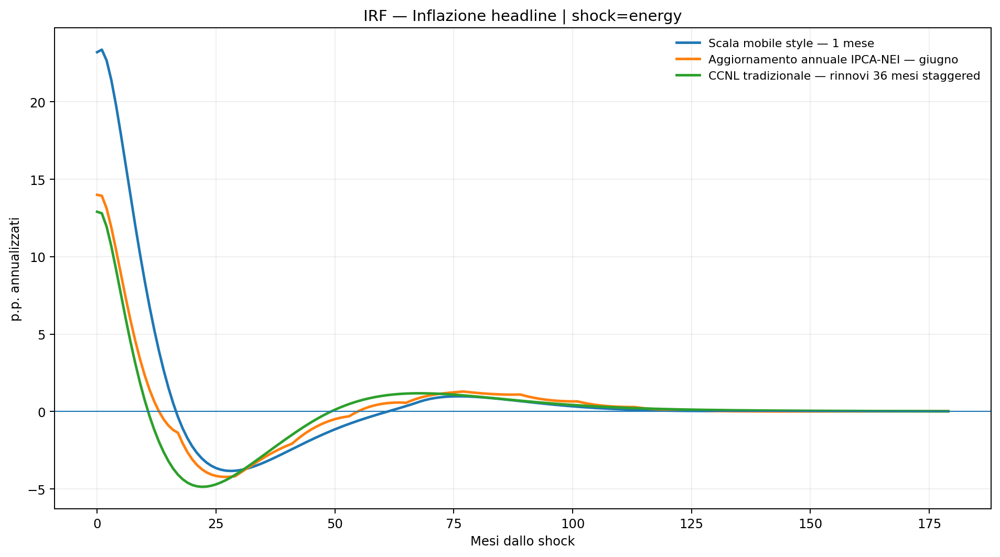

**Come leggere la variabile:** Inflazione complessiva. Nello shock energia reagisce subito alla componente importata e poi anche al pass-through core.

## pi_nei

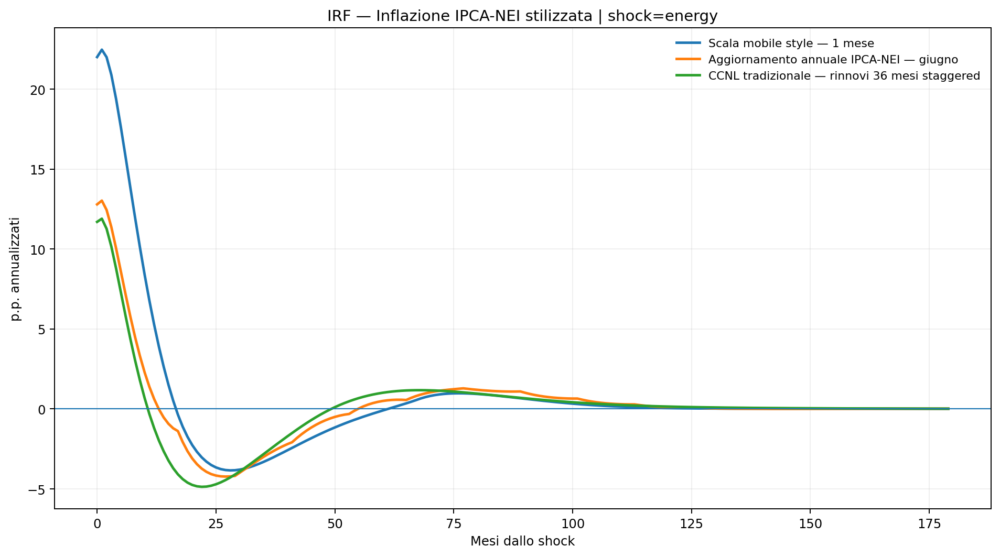

**Come leggere la variabile:** Esclude l'energia importata diretta. Lo shock energia entra solo con ritardo tramite xenergy_core.

## xenergy_core

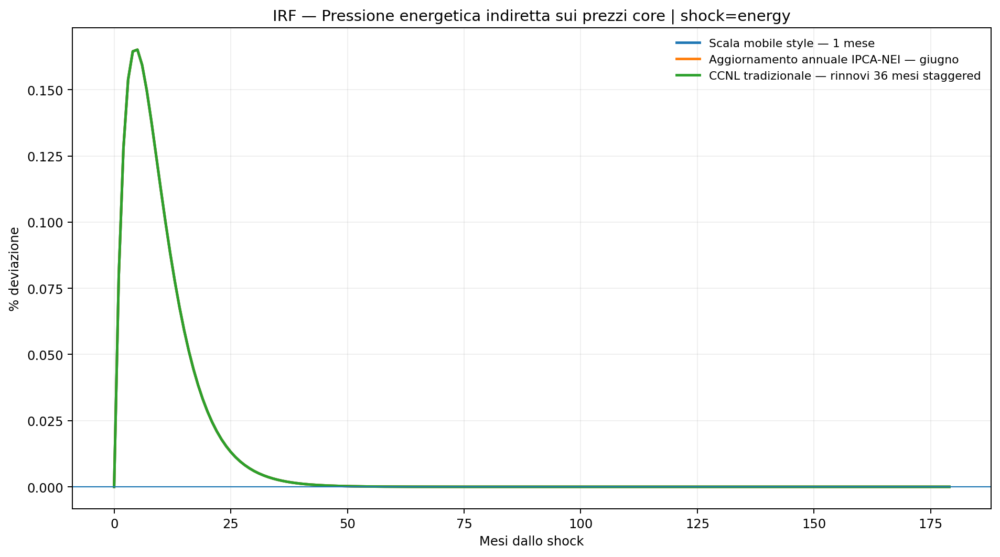

**Come leggere la variabile:** Stato che accumula gradualmente il pass-through dell'energia su input, trasporti, servizi e altri prezzi inclusi nel NEI.

## wpi_contract

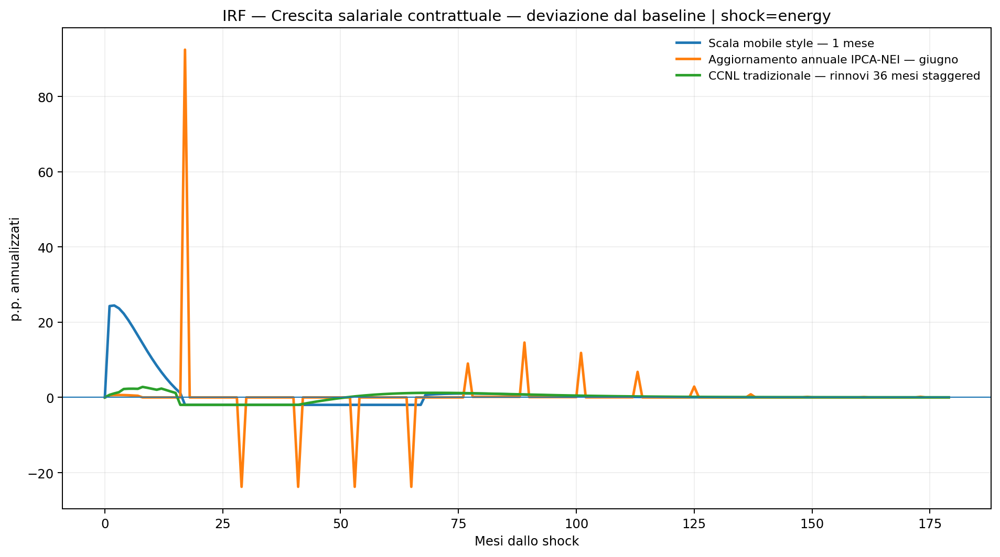

**Come leggere la variabile:** Deviazione dagli aumenti gia' previsti nel contratto. Nel tradizionale le tranche sull'inflazione prevista di base sono gia' nel baseline.

## wpi_indexation

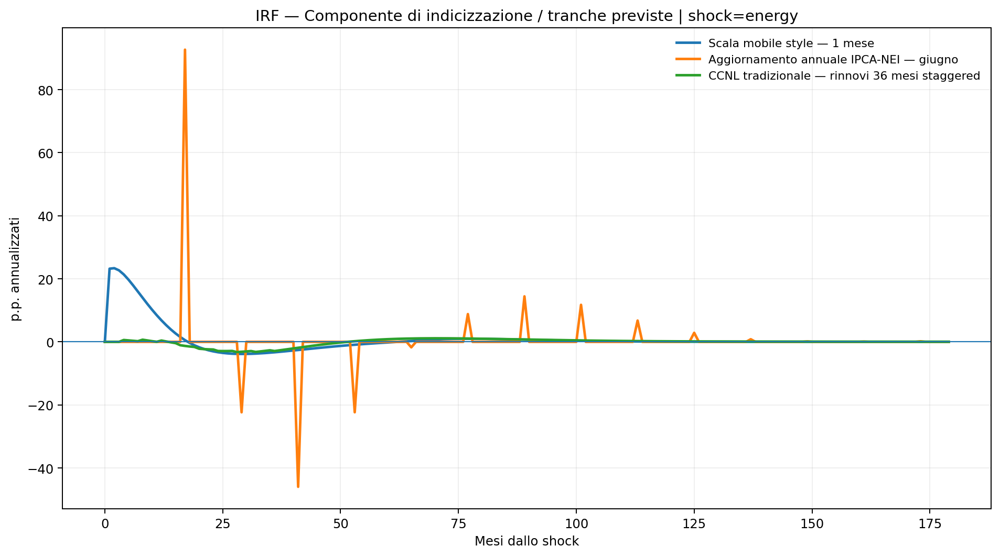

**Come leggere la variabile:** Mobile: headline mensile; annuale: NEI anno precedente a giugno; tradizionale: nuove tranche sulla previsione futura condizionata allo shock.

## wpi_catchup

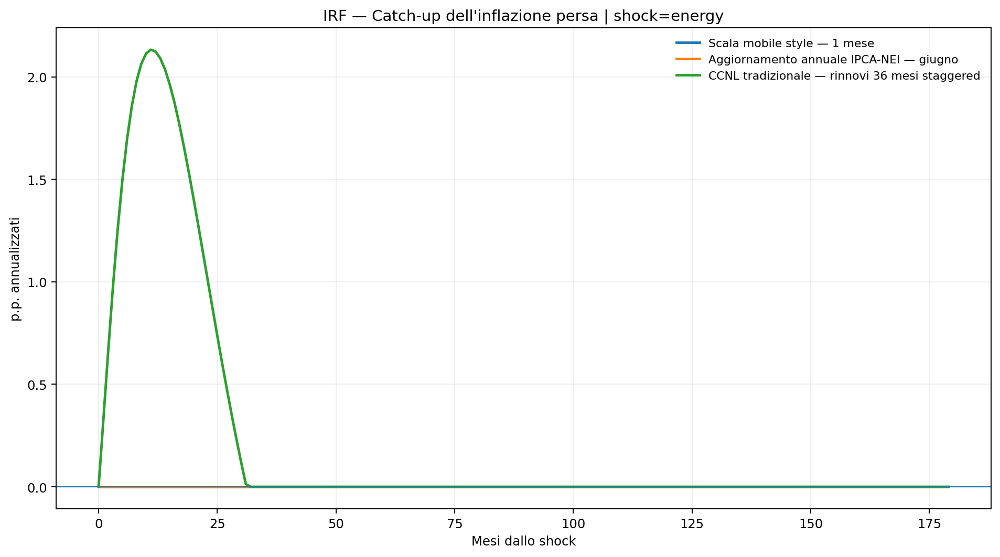

**Come leggere la variabile:** Recupero dell'errore positivo di inflazione non gia' compensato. Nel regime tradizionale avviene al rinnovo triennale staggered.

## wpi_bargaining

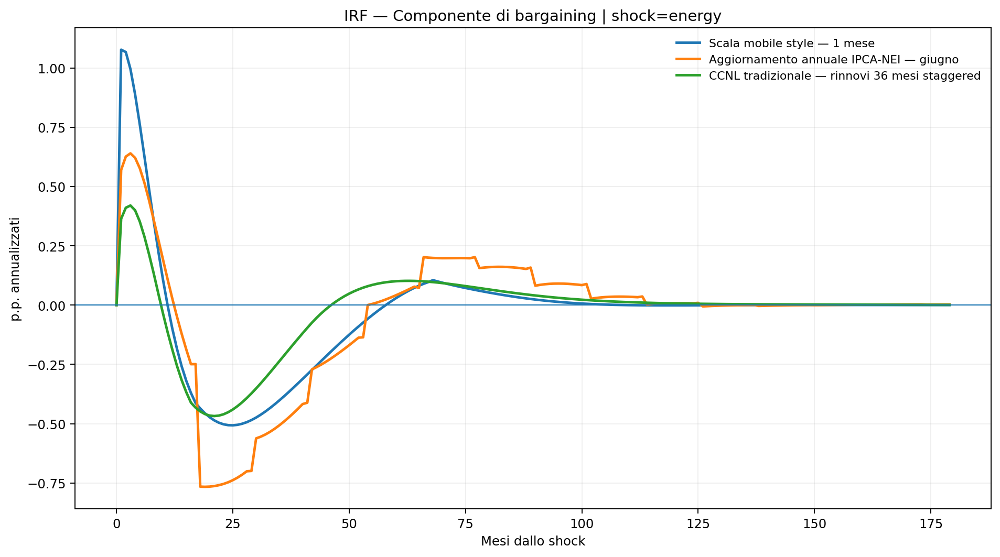

**Come leggere la variabile:** Aggiustamento reale verso il benchmark Nash. Ha sempre orologio separato di 36 mesi.

## wpi_drift

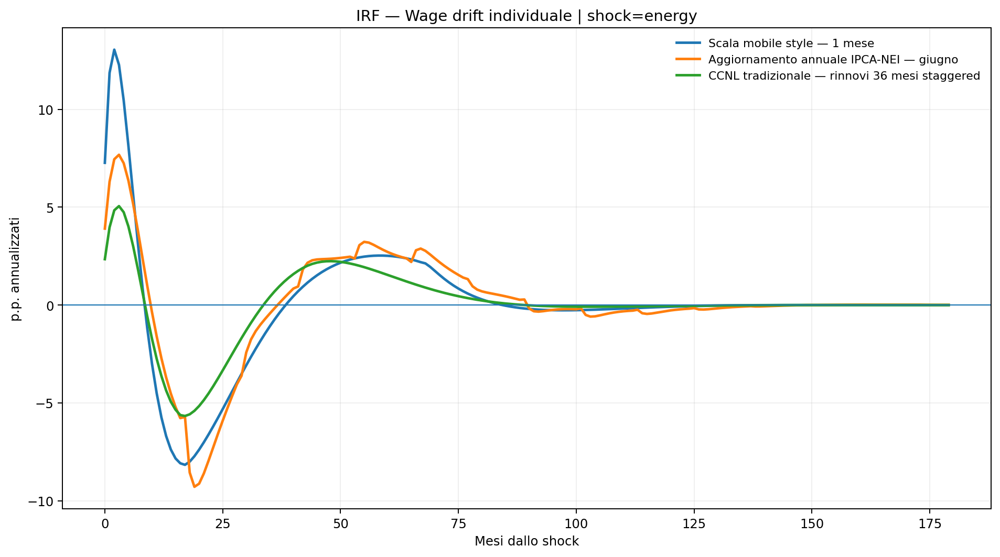

**Come leggere la variabile:** Superminimi, promozioni e aggiustamenti individuali: possono muoversi anche quando il minimo non viene aggiornato.

## wpi_eff

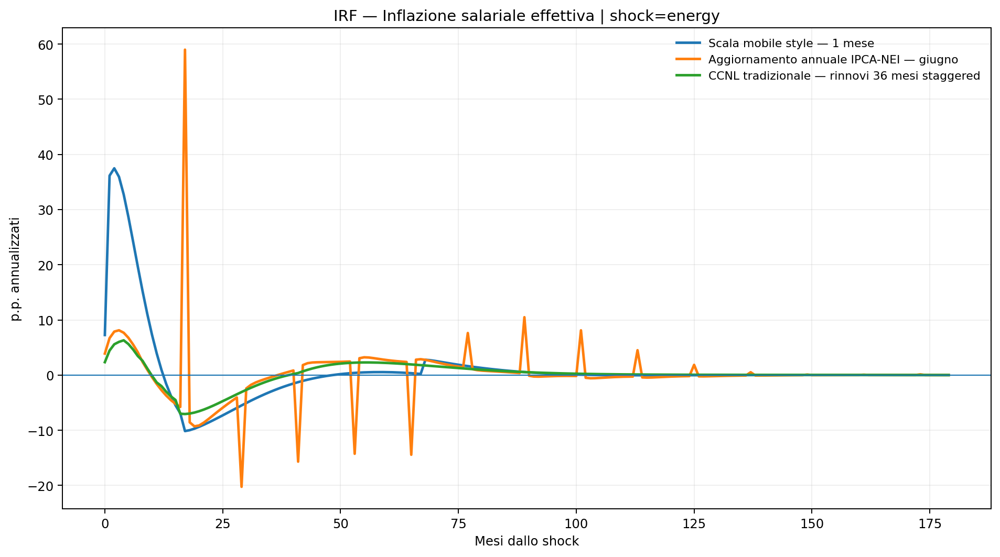

**Come leggere la variabile:** Somma della componente contrattuale trasmessa all'effettivo e del wage drift individuale.

## wmin_r

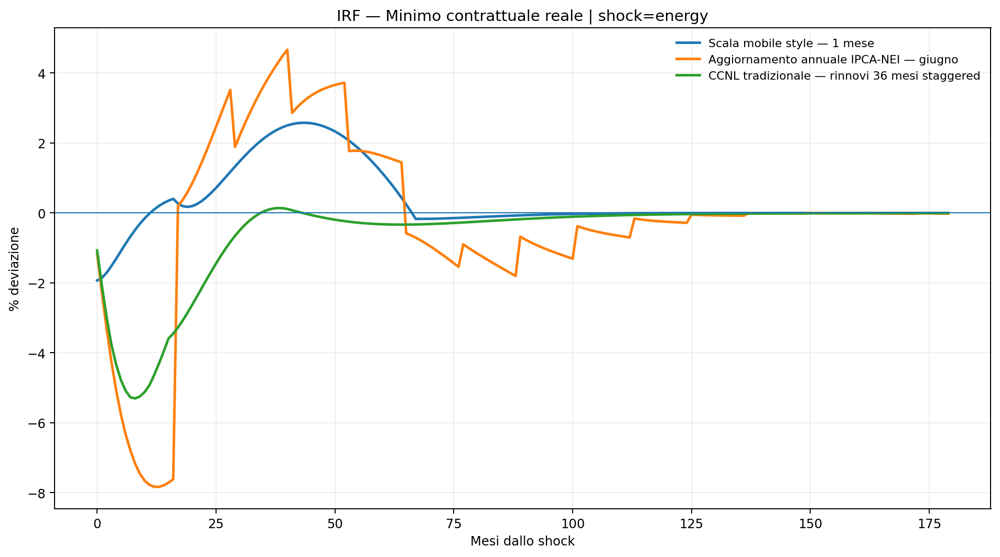

**Come leggere la variabile:** Potere d'acquisto del minimo rispetto al baseline contrattuale.

## weff_r

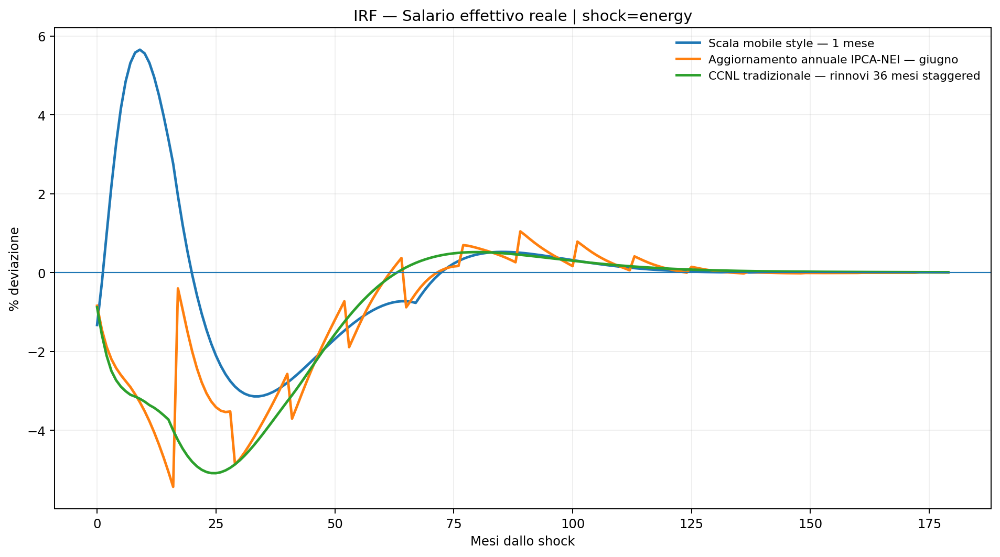

**Come leggere la variabile:** Retribuzione effettivamente pagata; e' questa, non il solo minimo, che entra nel costo marginale.

## wage_gap

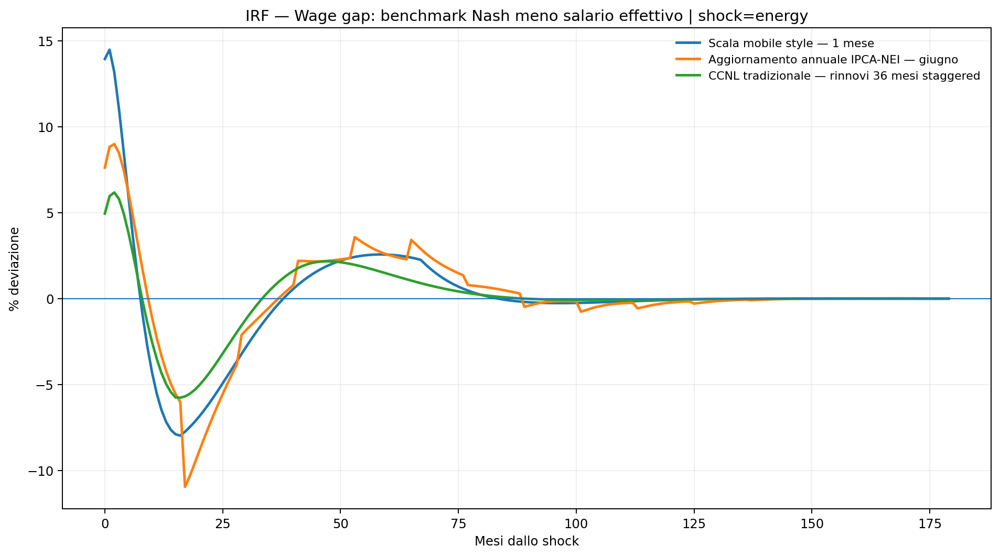

**Come leggere la variabile:** Positivo = salario effettivo sotto il benchmark; alimenta wage drift e bargaining.

## mc

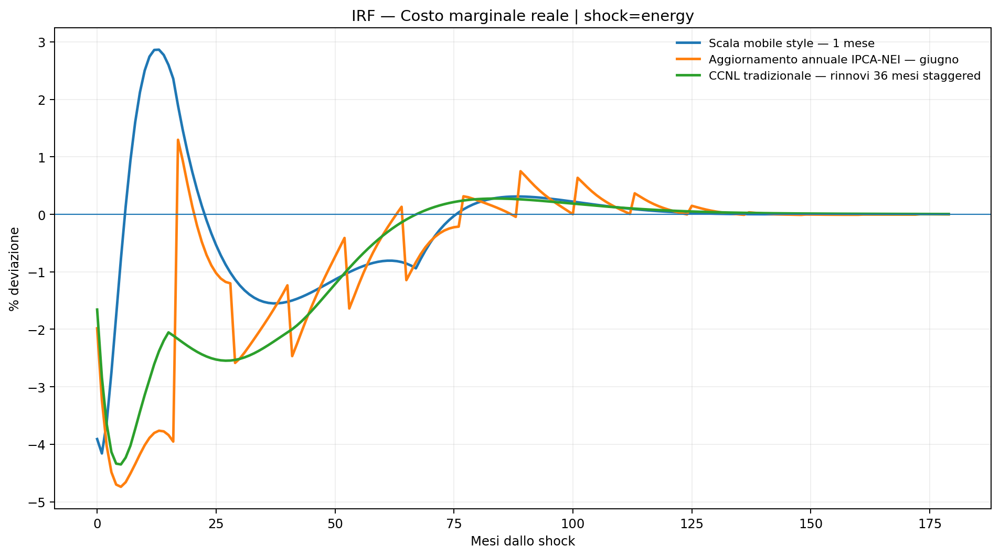

**Come leggere la variabile:** Ponte tra salario effettivo, produttivita' e inflazione NEI.

## i

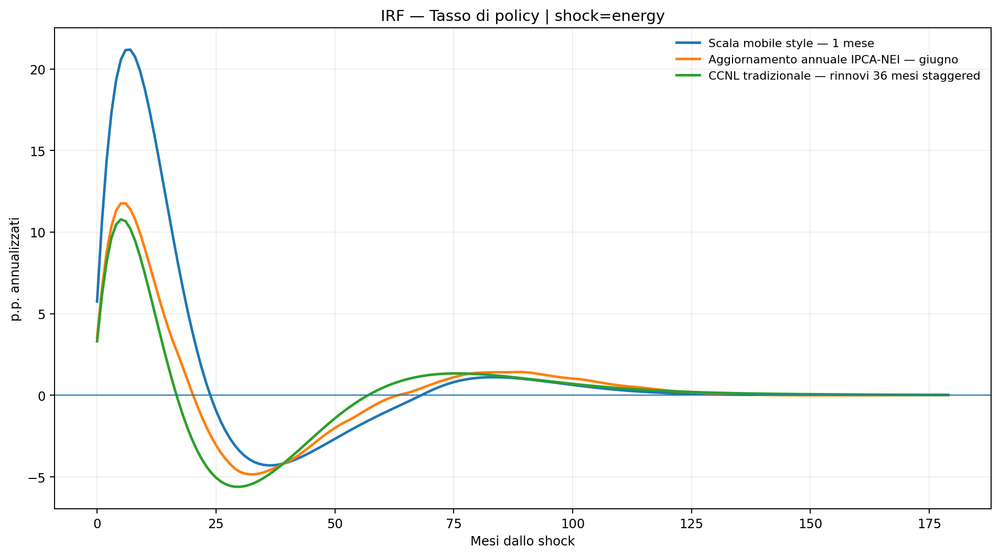

**Come leggere la variabile:** Risposta della banca centrale a inflazione e output.

## y

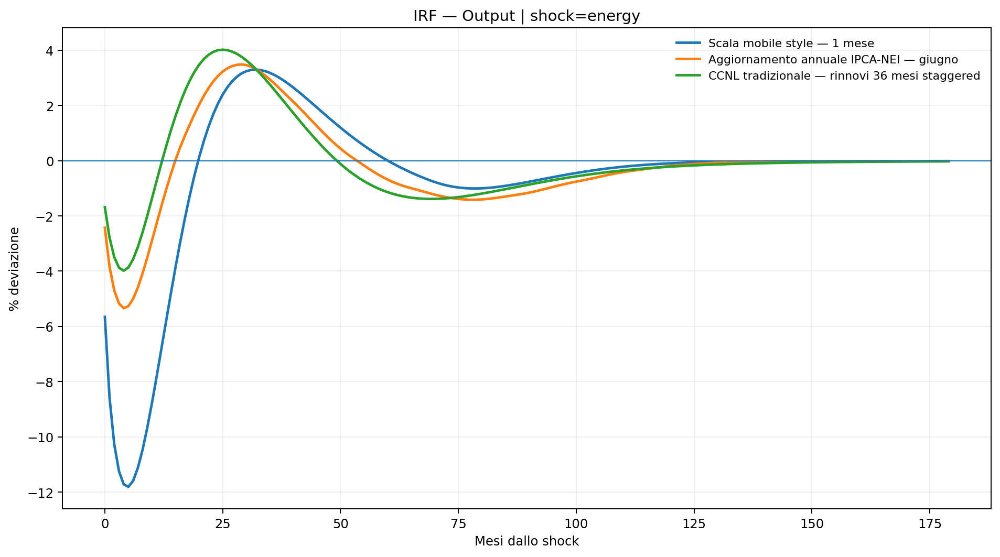

**Come leggere la variabile:** Produzione rispetto al sentiero di base.

## n

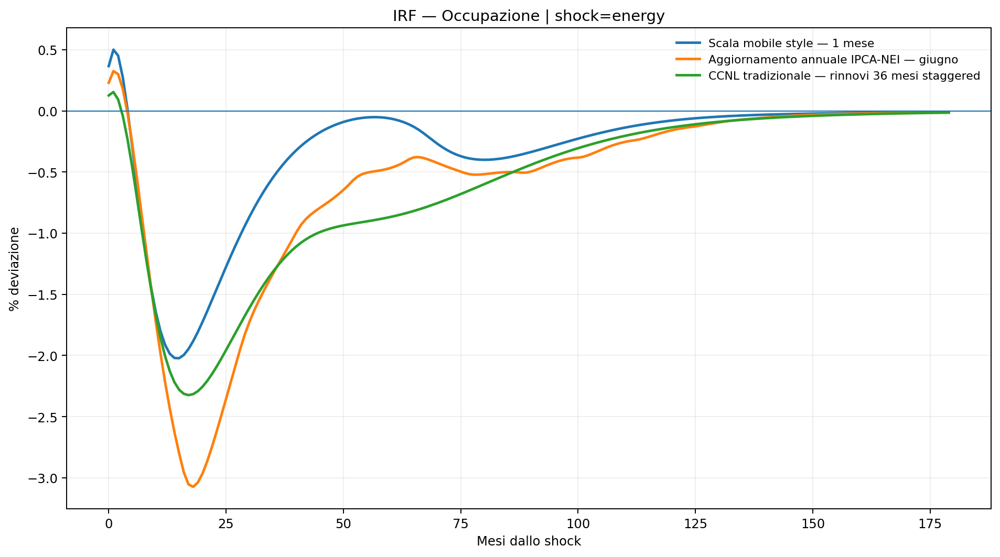

**Come leggere la variabile:** Stock di occupati generato da separazioni e nuovi match.

## u

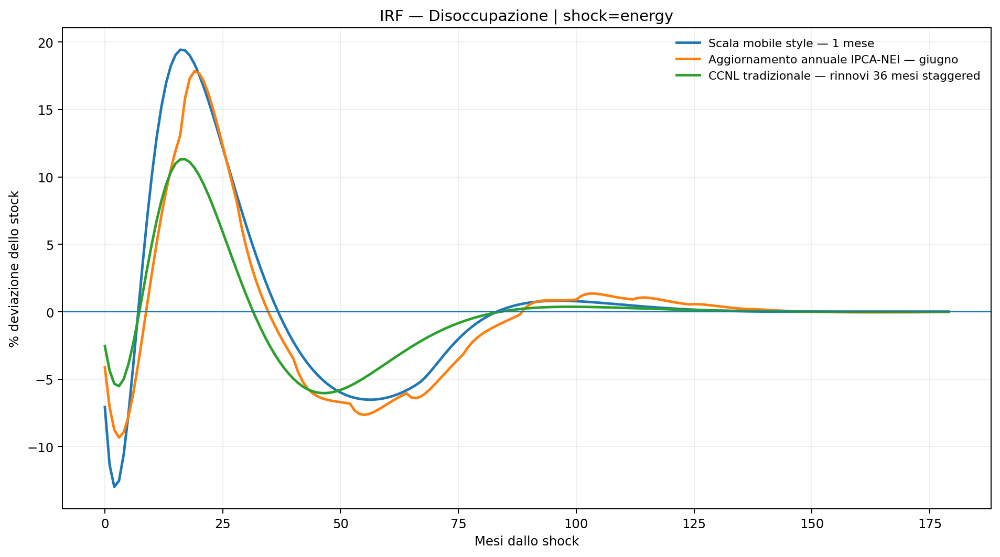

**Come leggere la variabile:** Stock U=L-N. Non leggere l'asse come punti percentuali del tasso ISTAT.

## lfp

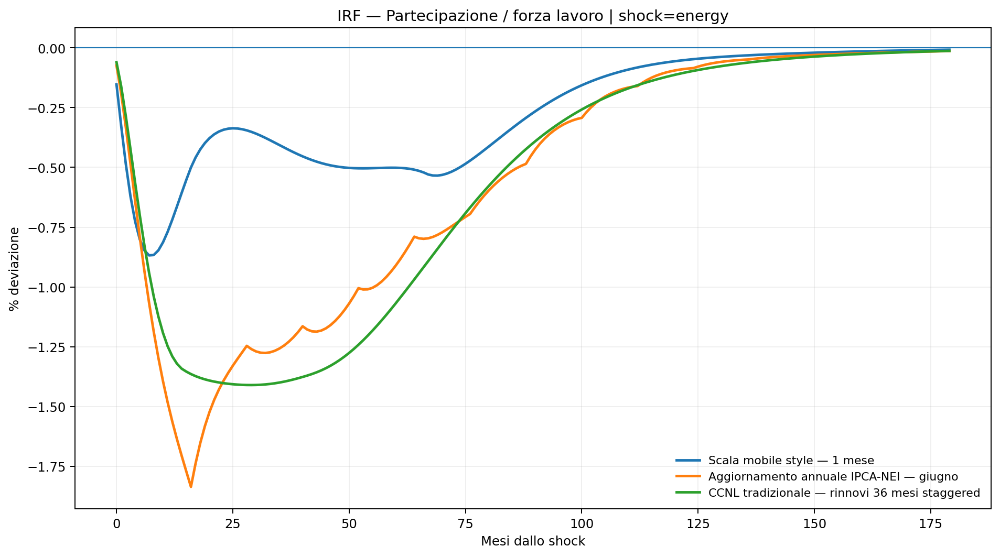

**Come leggere la variabile:** Entrata/uscita dalla forza lavoro in risposta a ciclo e salario reale.

## v

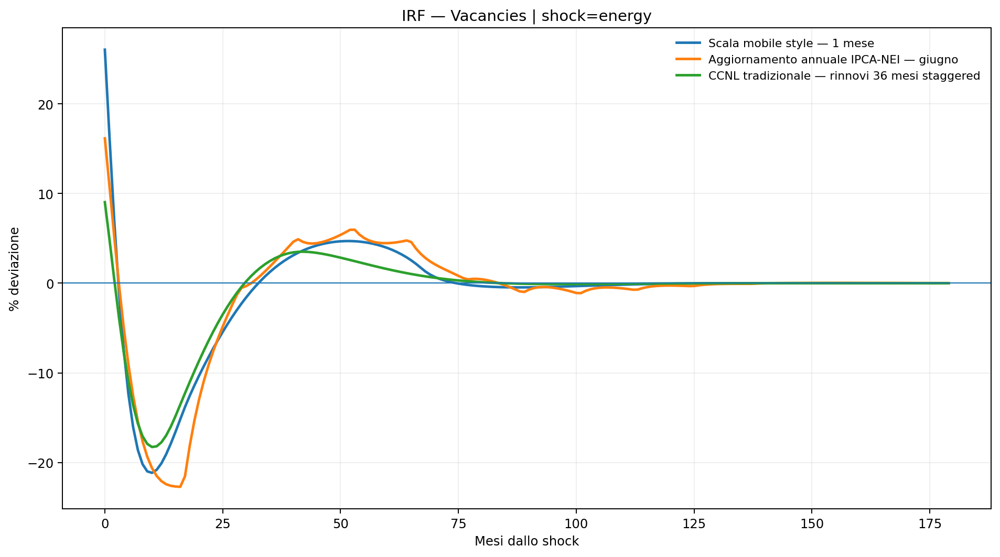

**Come leggere la variabile:** Domanda di lavoro delle imprese; utile per diagnosticare surplus eccessivi da salari reali bassi.

**⚠️ Diagnostica:** ATTENZIONE: max |IRF|=26.0% supera la soglia diagnostica del prototipo lineare.

## theta

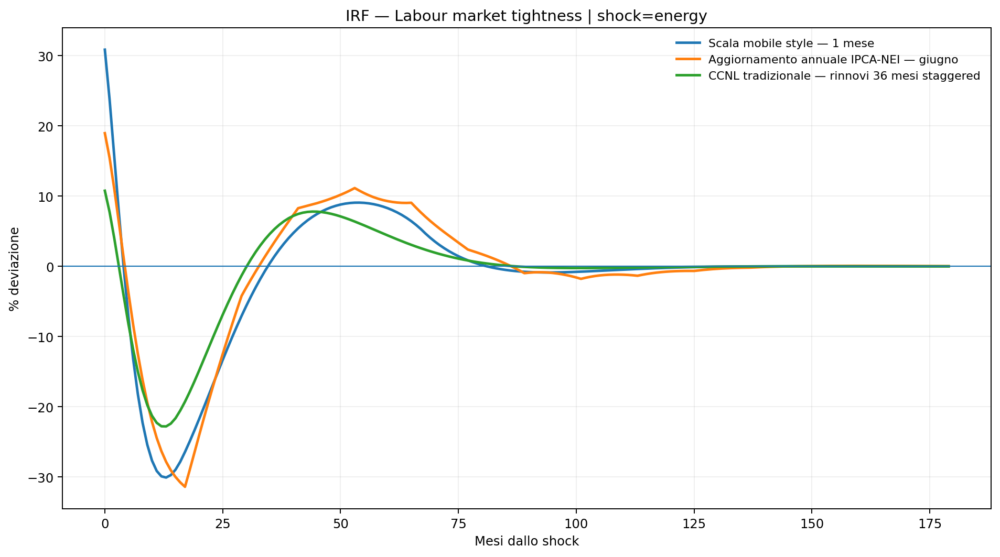

**Come leggere la variabile:** Vacancies relative ai searchers.

**⚠️ Diagnostica:** ATTENZIONE: max |IRF|=31.4% supera la soglia diagnostica del prototipo lineare.

## price_level_headline

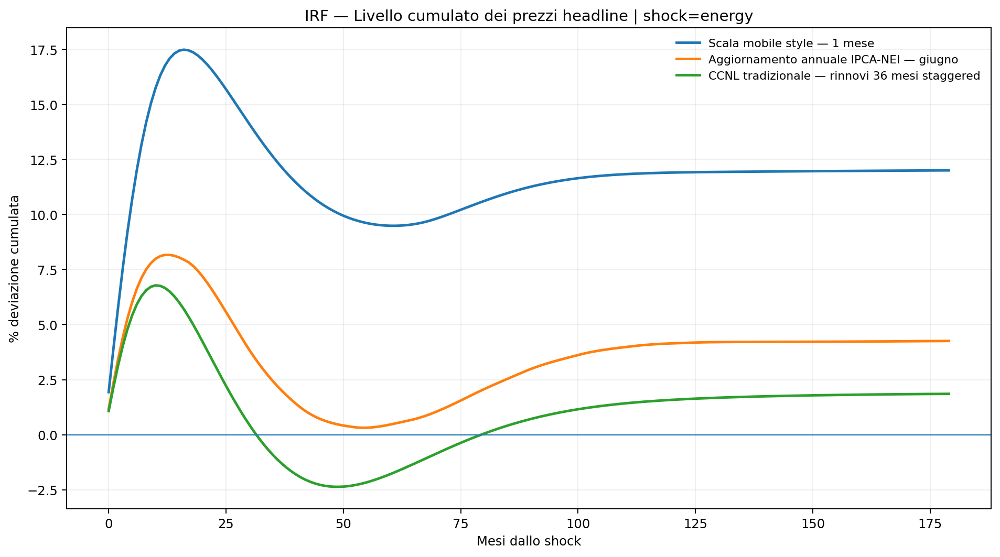

**Come leggere la variabile:** Somma dell'inflazione headline: mostra il livello dei prezzi, non solo il tasso.

## price_level_nei

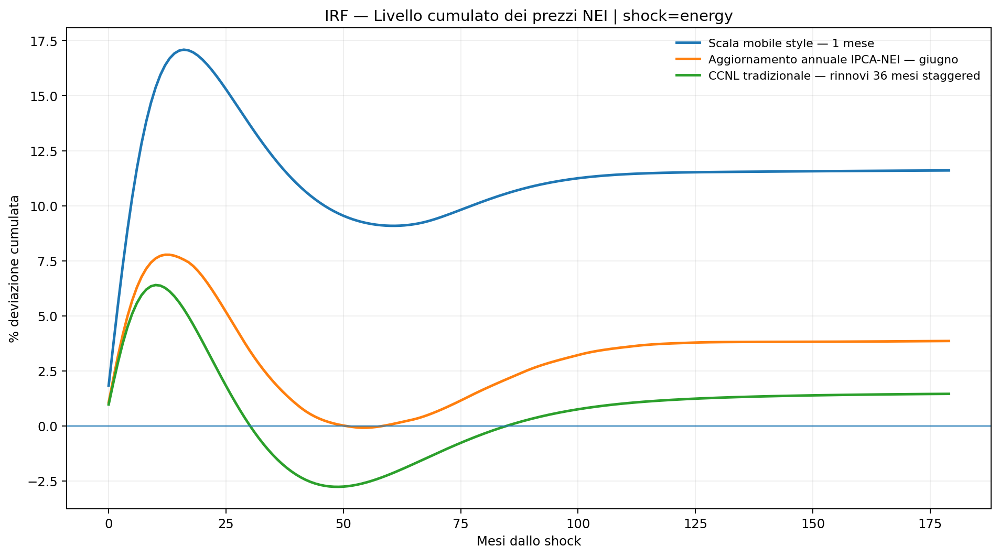

**Come leggere la variabile:** Livello cumulato della componente NEI/core.

## contract_wage_level

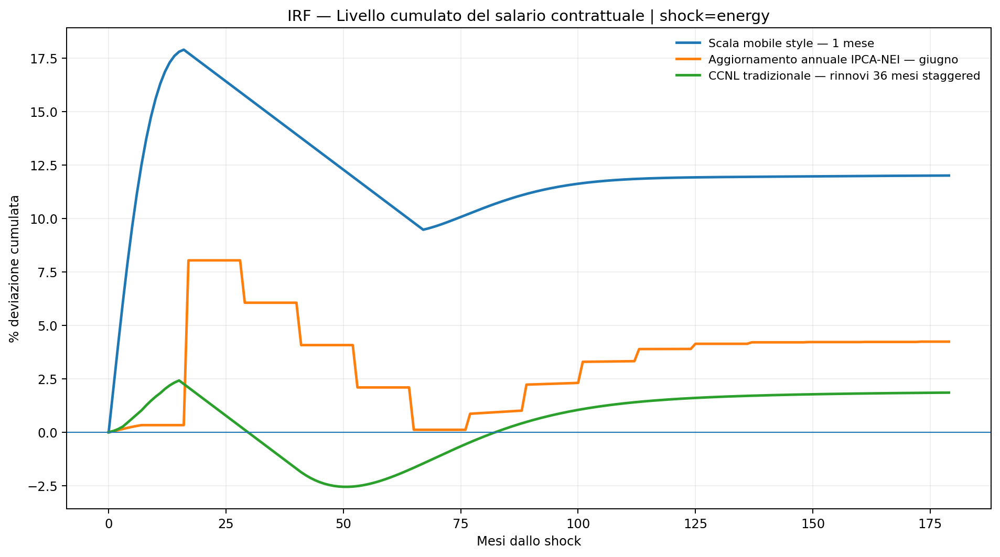

**Come leggere la variabile:** Deviazione cumulata rispetto al sentiero salariale contrattuale gia' programmato nel baseline.

## effective_wage_level

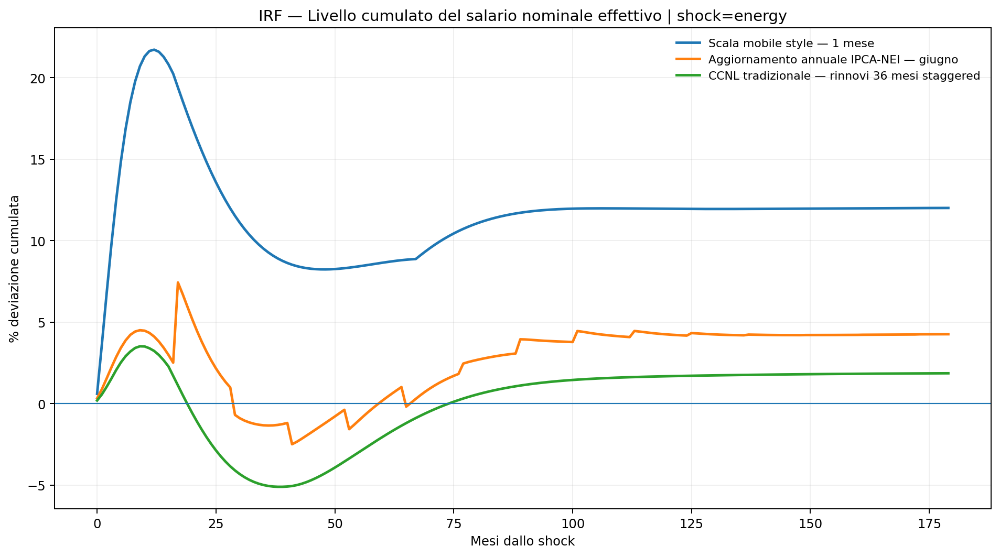

**Come leggere la variabile:** Include CCNL e wage drift; confrontalo con il livello dei prezzi.

**⚠️ Diagnostica:** ATTENZIONE: max |IRF|=21.7% supera la soglia diagnostica del prototipo lineare.

## Sintesi numerica delle IRF

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_headline,23.206167,23.369005,1,42.0,12.002431,True
1,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_nei,22.006167,22.469005,1,43.0,11.602431,True
2,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_contract,-0.000000,24.436015,2,15.0,NaN,True
3,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_eff,7.266499,37.482325,2,34.0,NaN,True
4,mobile_1m,Scala mobile style — 1 mese,1,headline,full,weff_r,-1.328306,5.651769,9,69.0,NaN,True
5,mobile_1m,Scala mobile style — 1 mese,1,headline,full,mc,-3.909107,-4.159264,1,71.0,NaN,True
6,mobile_1m,Scala mobile style — 1 mese,1,headline,full,y,-5.656198,-11.806789,5,51.0,NaN,True
7,mobile_1m,Scala mobile style — 1 mese,1,headline,full,n,0.365671,-2.022459,15,44.0,NaN,True
8,mobile_1m,Scala mobile style — 1 mese,1,headline,full,u,-7.068234,19.434326,16,76.0,NaN,True
9,mobile_1m,Scala mobile style — 1 mese,1,headline,full,v,26.032609,26.032609,0,65.0,NaN,True


## Benchmark diagnostico: nessuna indicizzazione automatica

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_headline,10.349086,10.349086,0,44.0,-2.491456,True
1,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_nei,9.149086,9.277678,1,44.0,-2.891456,True
2,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_contract,-0.000000,-0.751749,22,77.0,NaN,True
3,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_eff,-0.595732,-6.798565,17,91.0,NaN,True
4,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,weff_r,-0.912068,-6.613567,21,57.0,NaN,True
5,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,mc,-1.054453,-4.494361,6,59.0,NaN,True
6,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,y,-0.409542,5.172839,22,110.0,NaN,True
7,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,n,-0.077312,-2.551398,18,99.0,NaN,True
8,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,u,0.521230,12.696473,16,94.0,NaN,True
9,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,v,-4.837427,-20.083488,10,77.0,NaN,True


# ccnl_indexation_irf_institutional_technology

## pi_headline

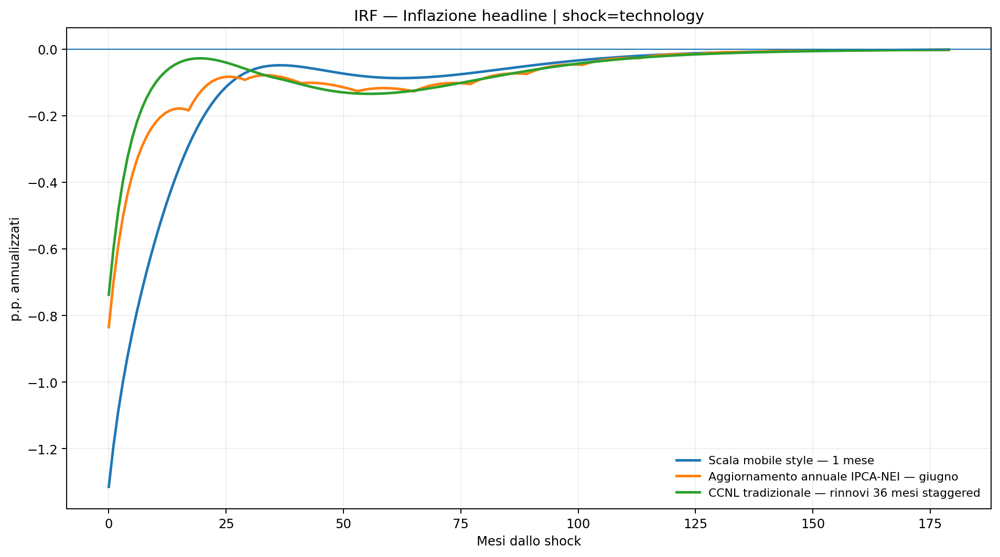

**Come leggere la variabile:** Inflazione complessiva. Nello shock energia reagisce subito alla componente importata e poi anche al pass-through core.

## pi_nei

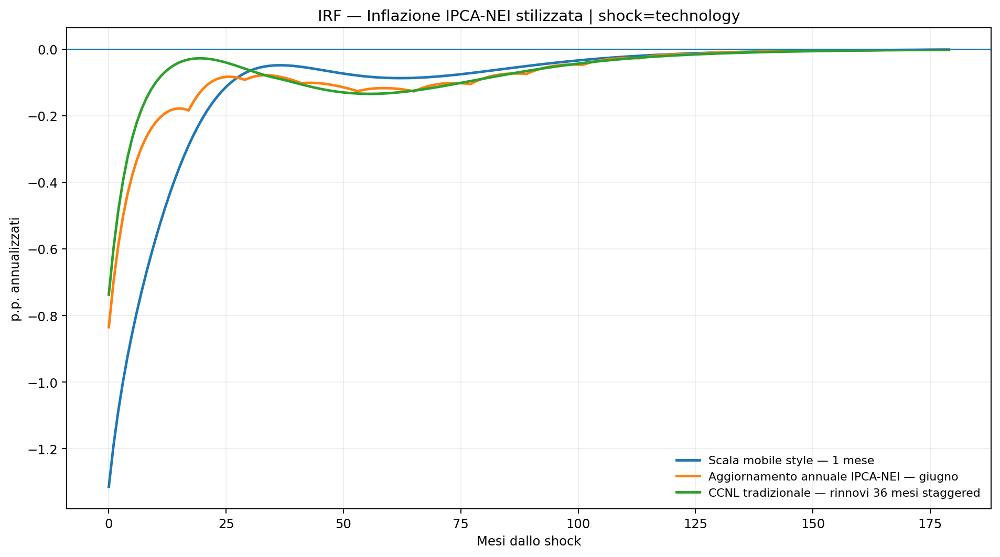

**Come leggere la variabile:** Esclude l'energia importata diretta. Lo shock energia entra solo con ritardo tramite xenergy_core.

## xenergy_core

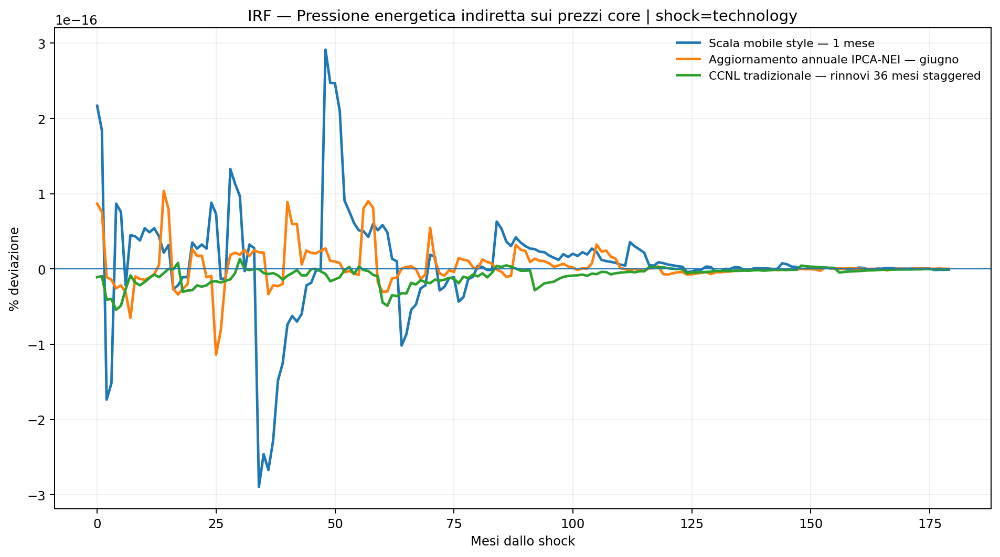

**Come leggere la variabile:** Stato che accumula gradualmente il pass-through dell'energia su input, trasporti, servizi e altri prezzi inclusi nel NEI.

## wpi_contract

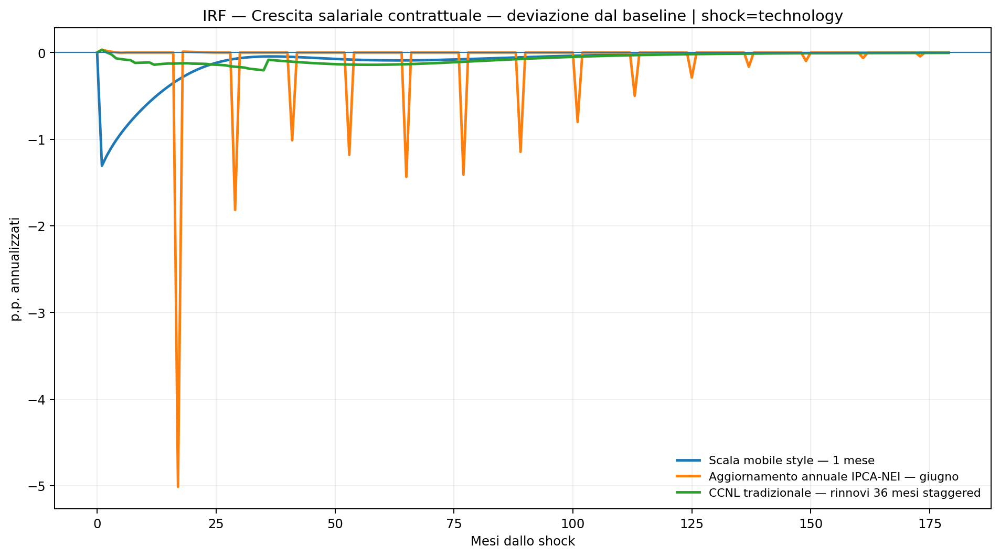

**Come leggere la variabile:** Deviazione dagli aumenti gia' previsti nel contratto. Nel tradizionale le tranche sull'inflazione prevista di base sono gia' nel baseline.

## wpi_indexation

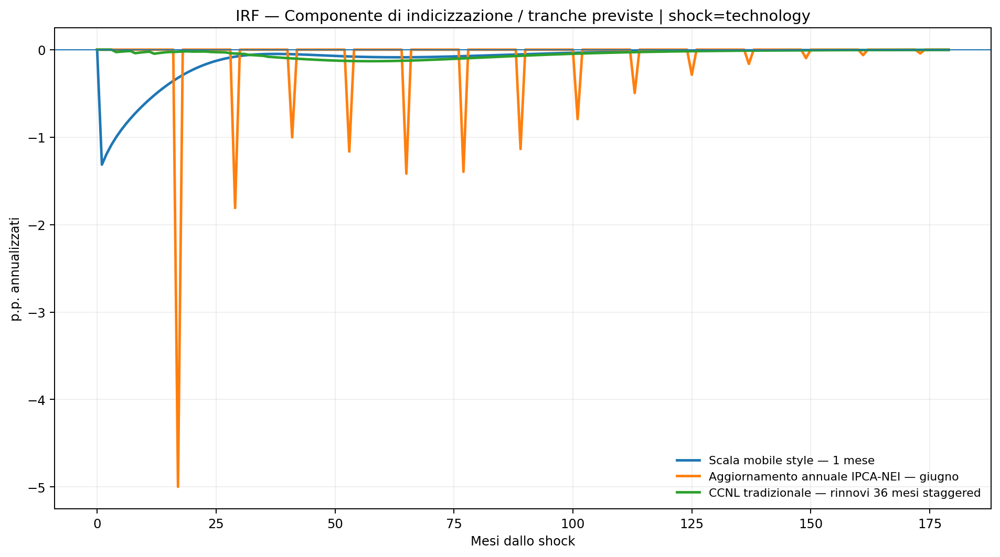

**Come leggere la variabile:** Mobile: headline mensile; annuale: NEI anno precedente a giugno; tradizionale: nuove tranche sulla previsione futura condizionata allo shock.

## wpi_catchup

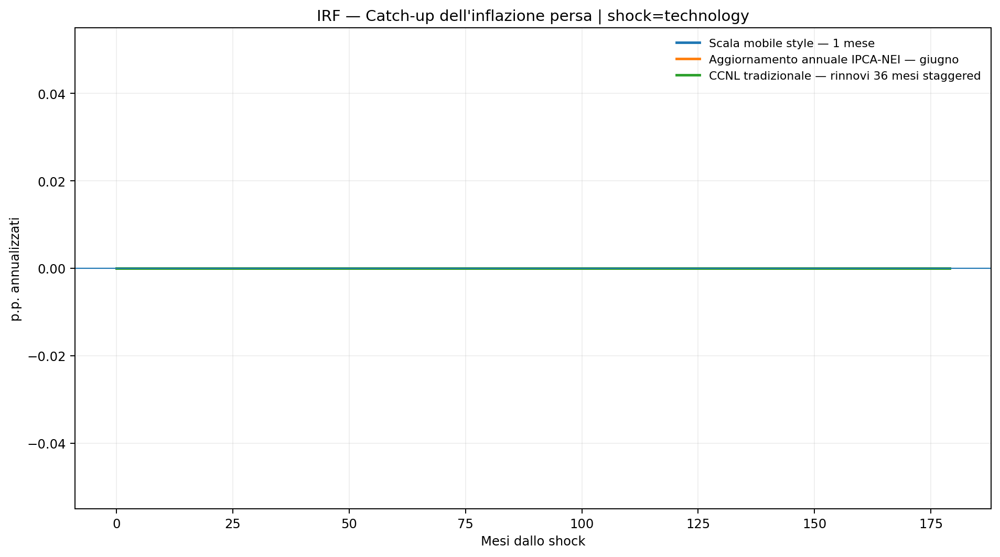

**Come leggere la variabile:** Recupero dell'errore positivo di inflazione non gia' compensato. Nel regime tradizionale avviene al rinnovo triennale staggered.

## wpi_bargaining

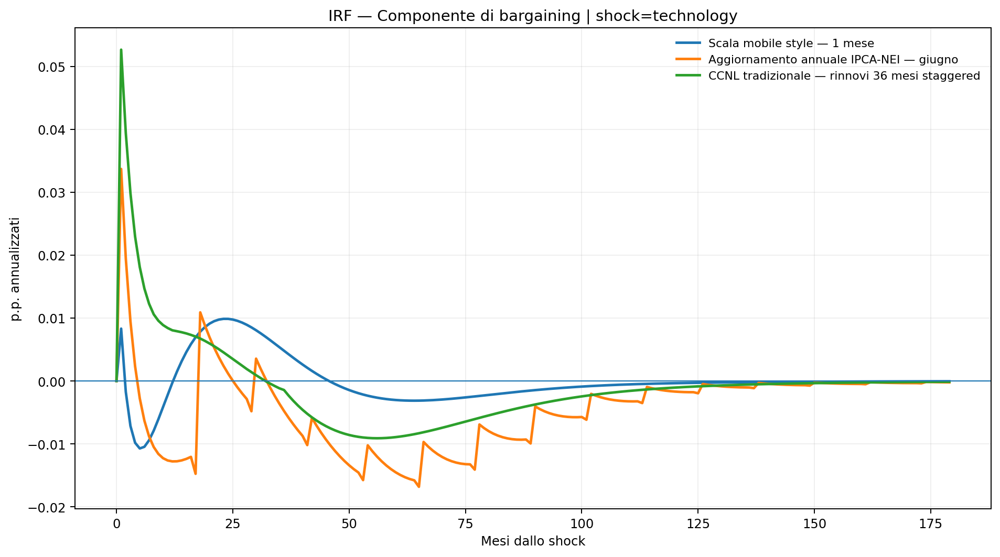

**Come leggere la variabile:** Aggiustamento reale verso il benchmark Nash. Ha sempre orologio separato di 36 mesi.

## wpi_drift

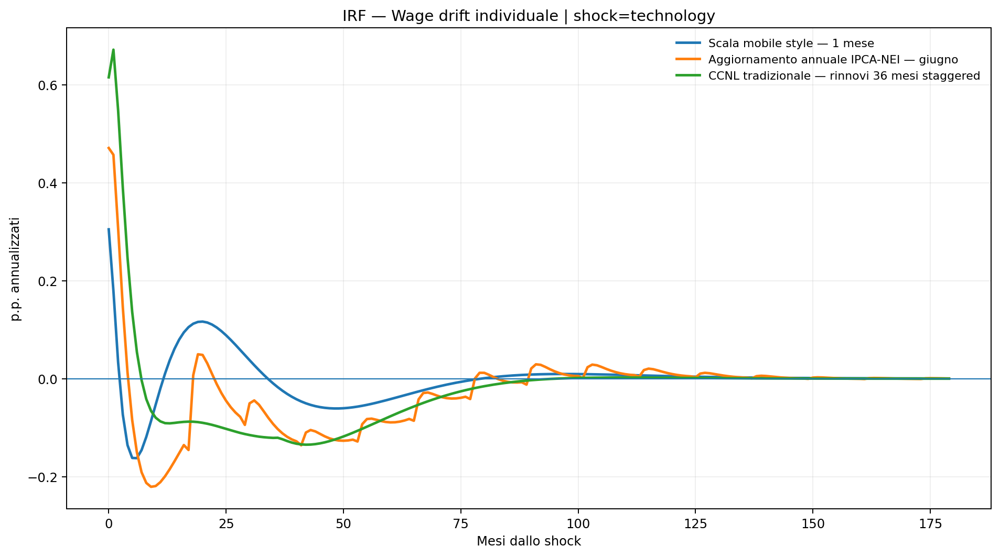

**Come leggere la variabile:** Superminimi, promozioni e aggiustamenti individuali: possono muoversi anche quando il minimo non viene aggiornato.

## wpi_eff

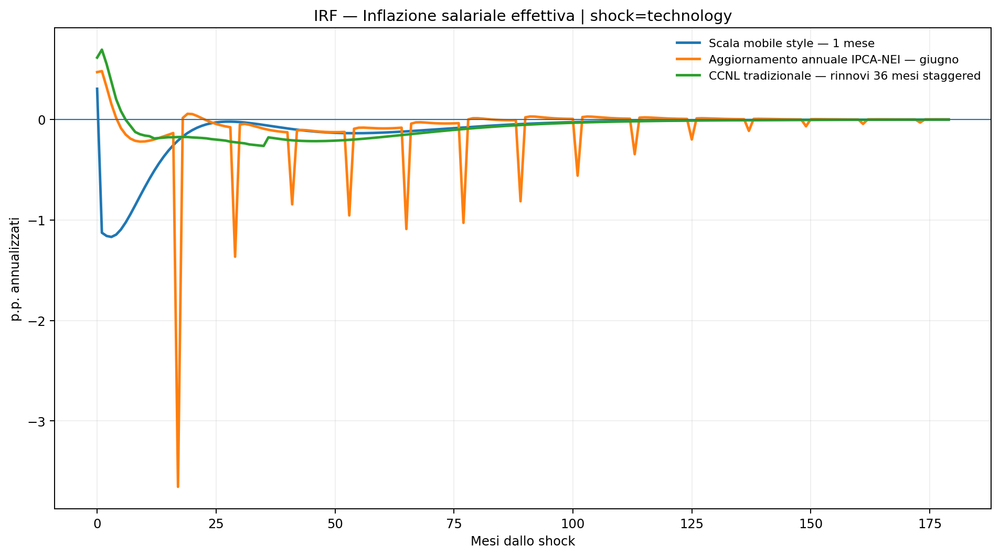

**Come leggere la variabile:** Somma della componente contrattuale trasmessa all'effettivo e del wage drift individuale.

## wmin_r

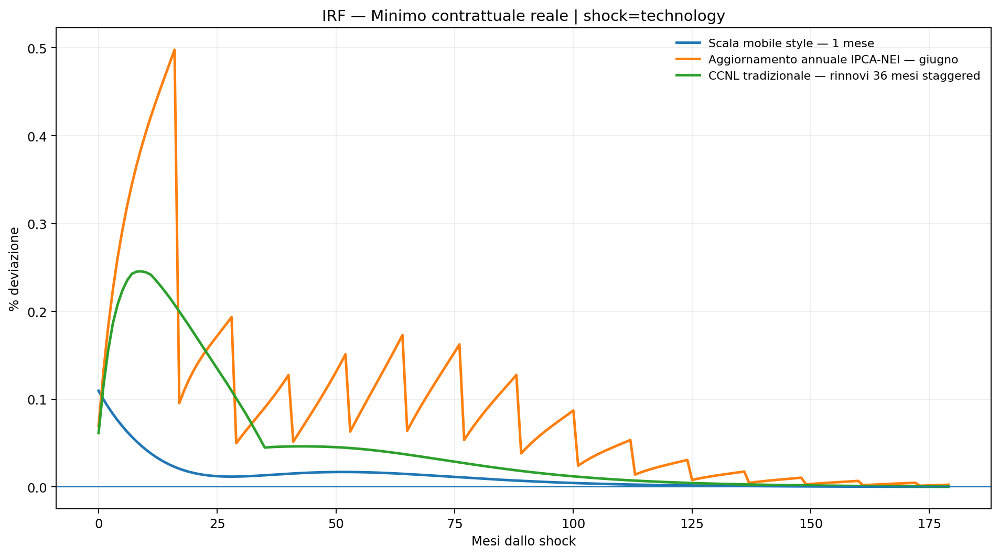

**Come leggere la variabile:** Potere d'acquisto del minimo rispetto al baseline contrattuale.

## weff_r

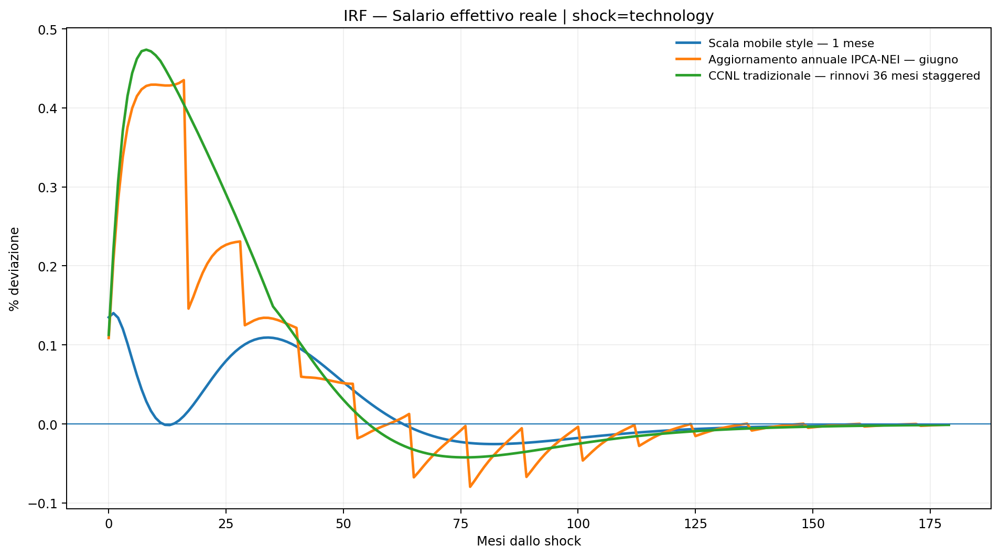

**Come leggere la variabile:** Retribuzione effettivamente pagata; e' questa, non il solo minimo, che entra nel costo marginale.

## wage_gap

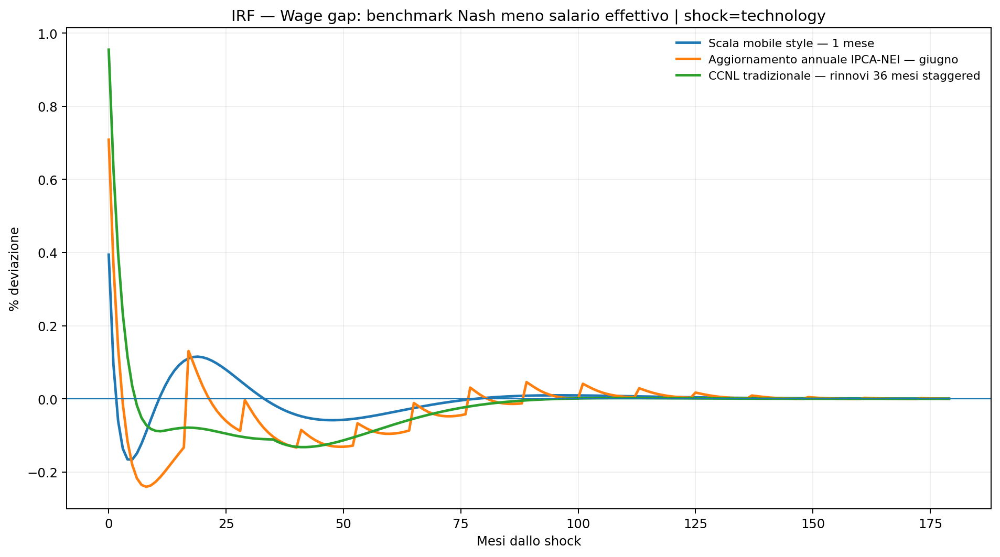

**Come leggere la variabile:** Positivo = salario effettivo sotto il benchmark; alimenta wage drift e bargaining.

## mc

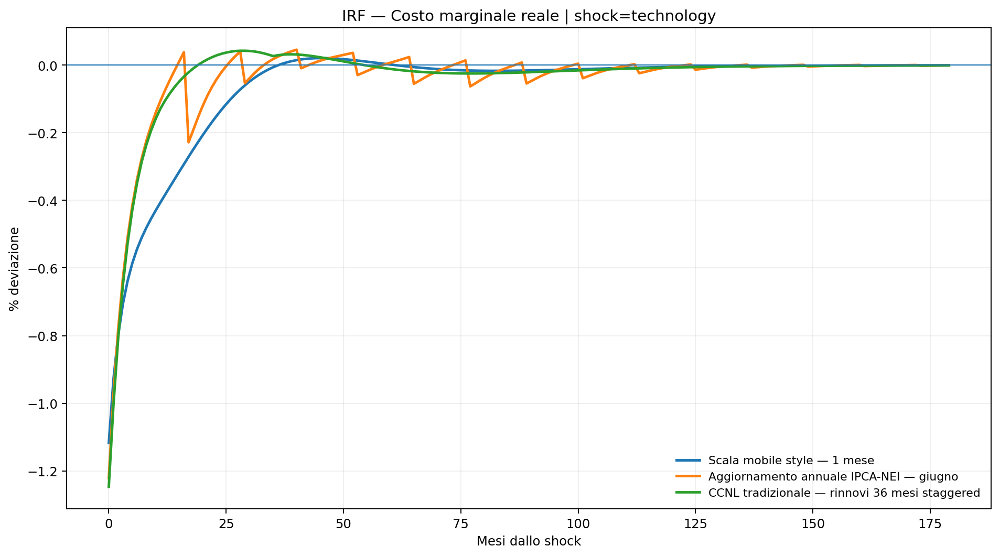

**Come leggere la variabile:** Ponte tra salario effettivo, produttivita' e inflazione NEI.

## i

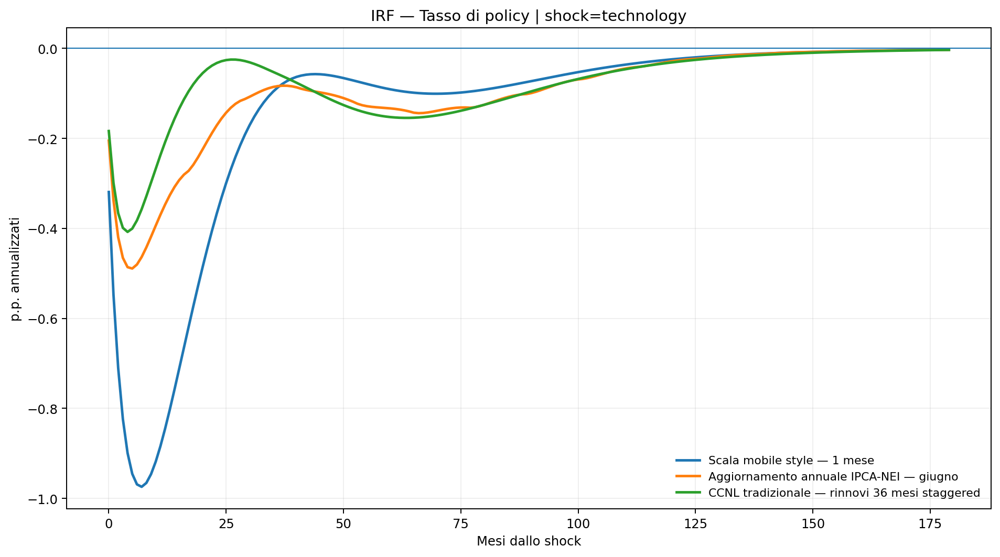

**Come leggere la variabile:** Risposta della banca centrale a inflazione e output.

## y

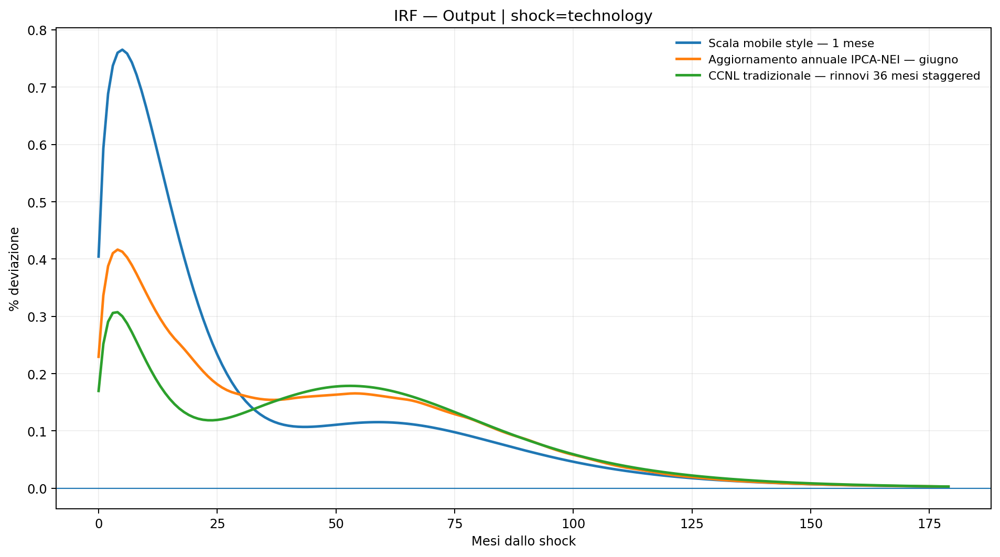

**Come leggere la variabile:** Produzione rispetto al sentiero di base.

## n

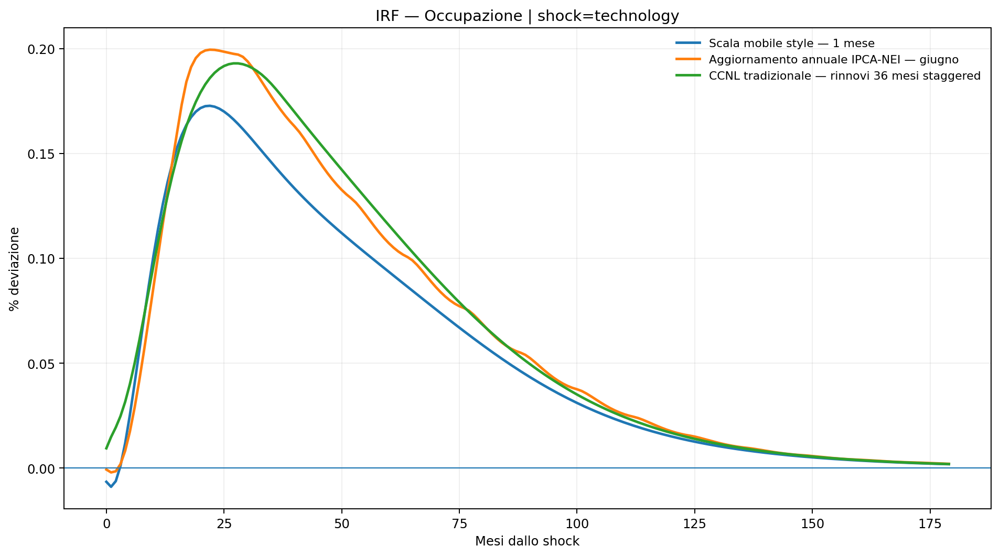

**Come leggere la variabile:** Stock di occupati generato da separazioni e nuovi match.

## u

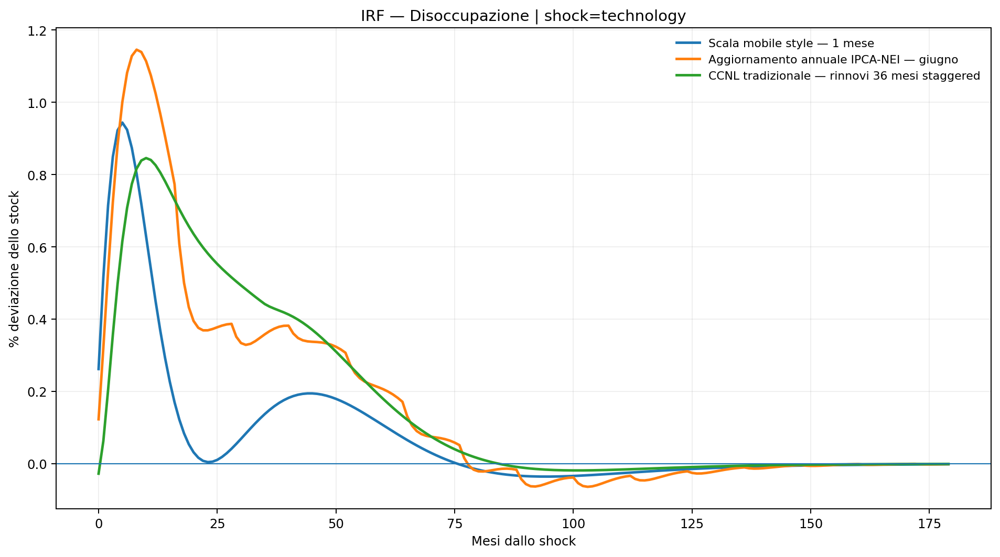

**Come leggere la variabile:** Stock U=L-N. Non leggere l'asse come punti percentuali del tasso ISTAT.

## lfp

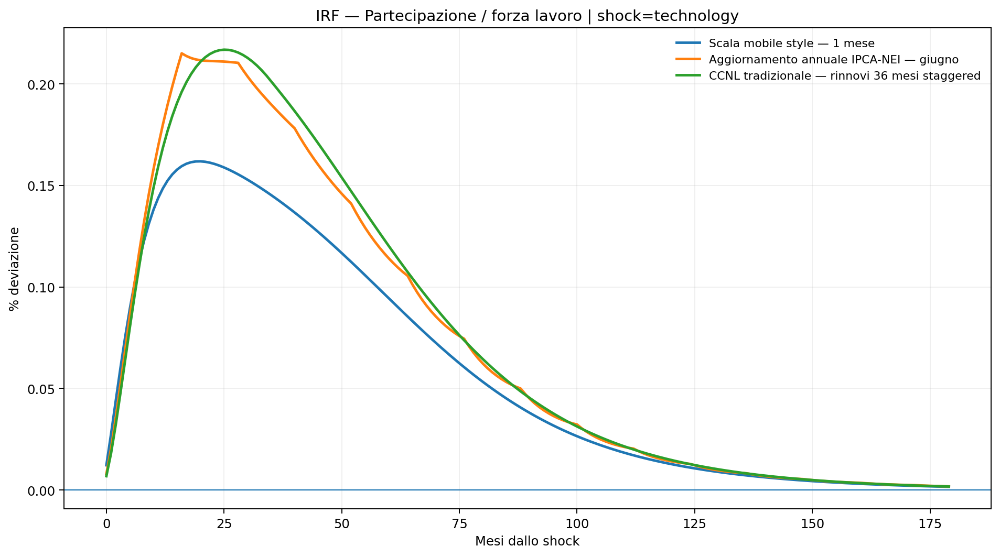

**Come leggere la variabile:** Entrata/uscita dalla forza lavoro in risposta a ciclo e salario reale.

## v

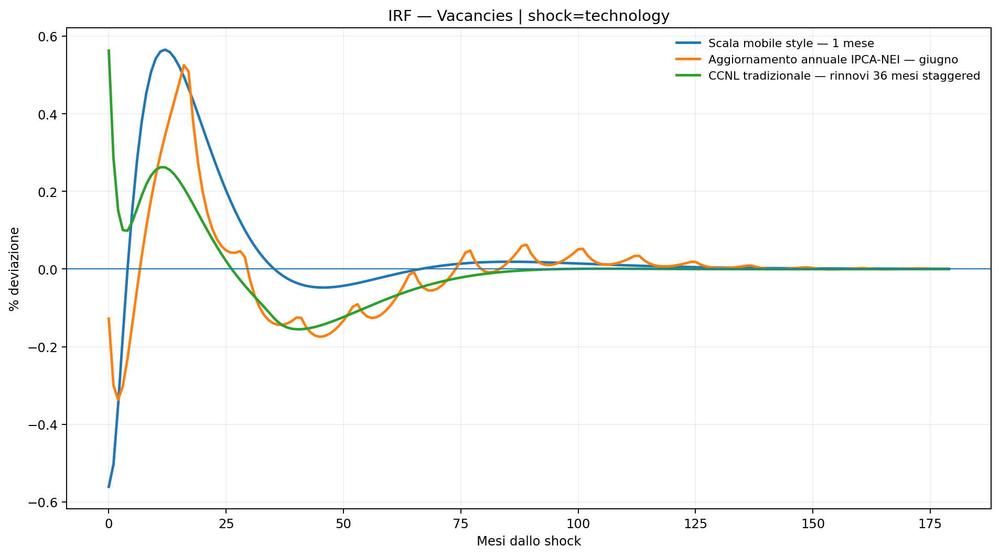

**Come leggere la variabile:** Domanda di lavoro delle imprese; utile per diagnosticare surplus eccessivi da salari reali bassi.

## theta

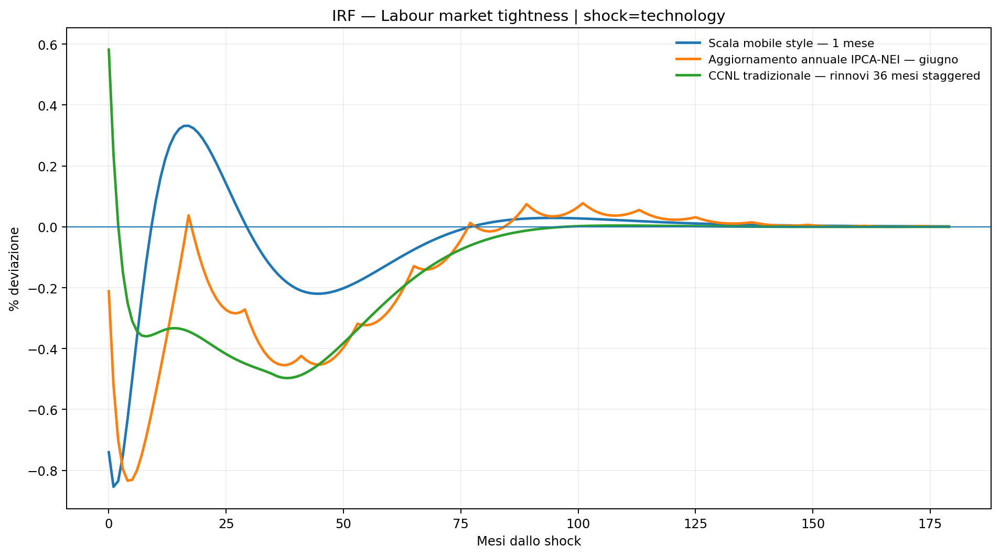

**Come leggere la variabile:** Vacancies relative ai searchers.

## price_level_headline

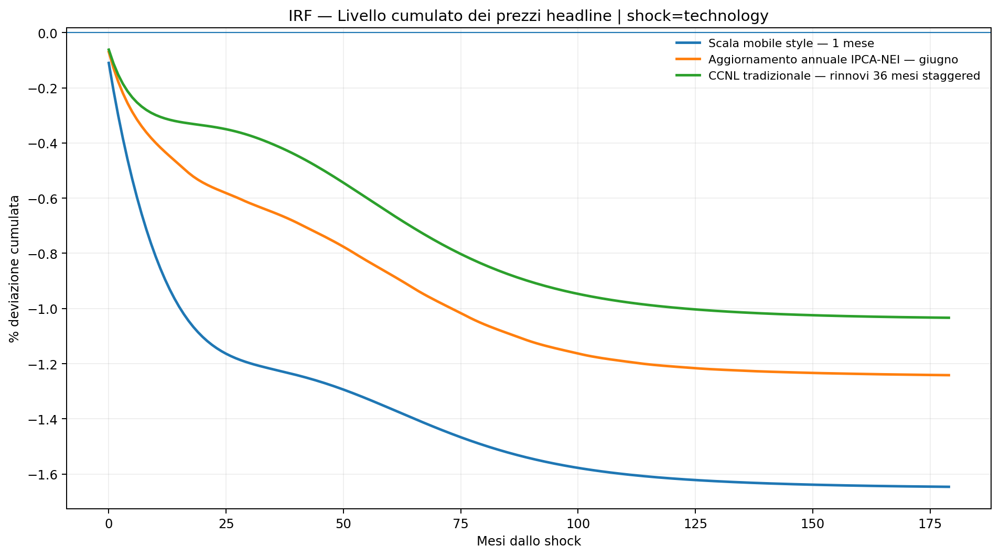

**Come leggere la variabile:** Somma dell'inflazione headline: mostra il livello dei prezzi, non solo il tasso.

## price_level_nei

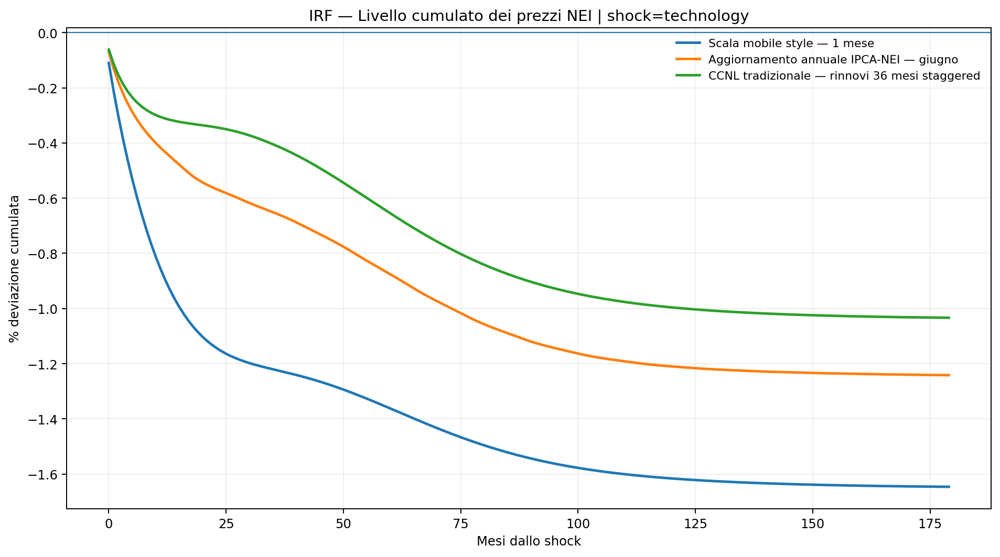

**Come leggere la variabile:** Livello cumulato della componente NEI/core.

## contract_wage_level

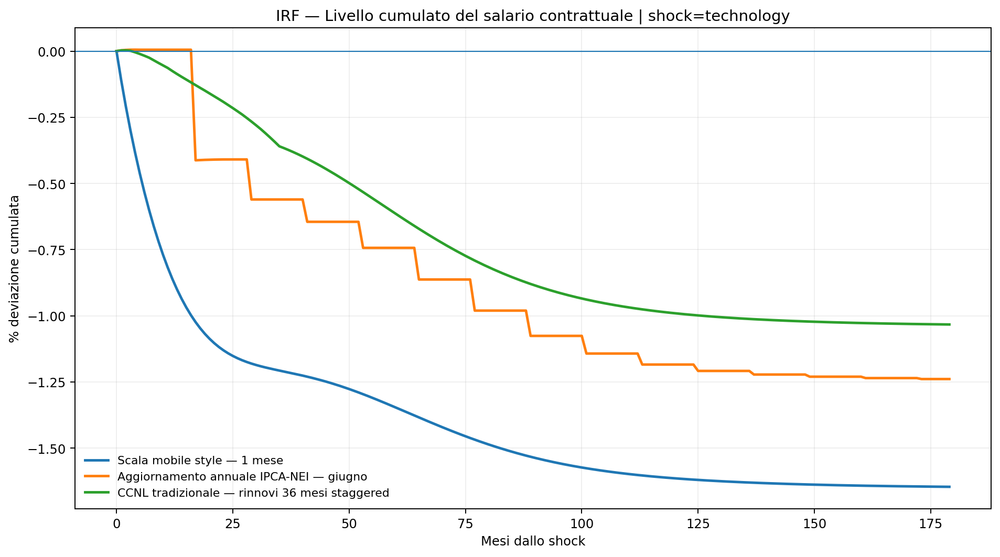

**Come leggere la variabile:** Deviazione cumulata rispetto al sentiero salariale contrattuale gia' programmato nel baseline.

## effective_wage_level

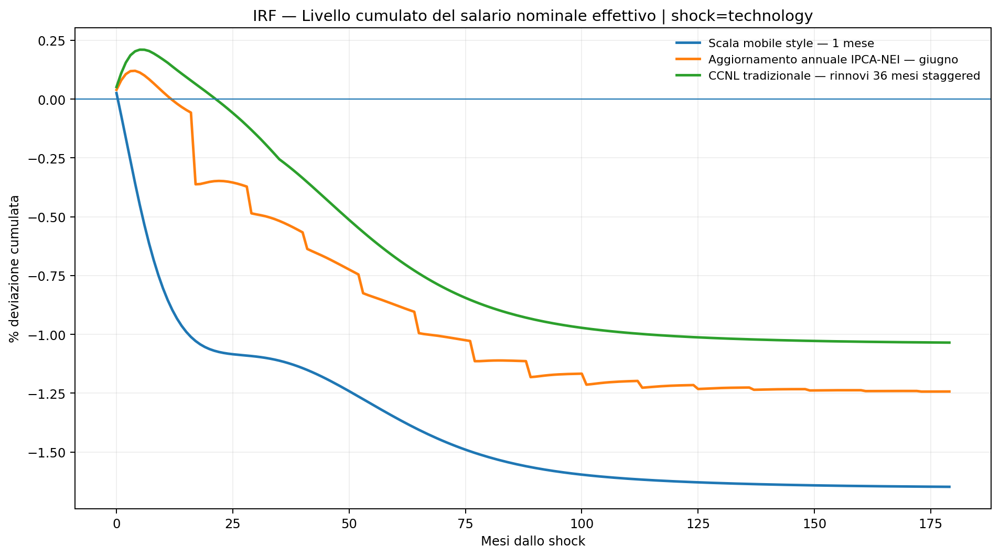

**Come leggere la variabile:** Include CCNL e wage drift; confrontalo con il livello dei prezzi.

## Sintesi numerica delle IRF

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_headline,-1.314454,-1.314454,0,24.0,-1.646581,True
1,mobile_1m,Scala mobile style — 1 mese,1,headline,full,pi_nei,-1.314454,-1.314454,0,24.0,-1.646581,True
2,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_contract,-0.000000,-1.306135,1,25.0,NaN,True
3,mobile_1m,Scala mobile style — 1 mese,1,headline,full,wpi_eff,0.304816,-1.169048,3,20.0,NaN,True
4,mobile_1m,Scala mobile style — 1 mese,1,headline,full,weff_r,0.134939,0.140276,1,107.0,NaN,True
5,mobile_1m,Scala mobile style — 1 mese,1,headline,full,mc,-1.117526,-1.117526,0,26.0,NaN,True
6,mobile_1m,Scala mobile style — 1 mese,1,headline,full,y,0.404326,0.765415,5,85.0,NaN,True
7,mobile_1m,Scala mobile style — 1 mese,1,headline,full,n,-0.006588,0.172744,22,117.0,NaN,True
8,mobile_1m,Scala mobile style — 1 mese,1,headline,full,u,0.261768,0.943980,5,18.0,NaN,True
9,mobile_1m,Scala mobile style — 1 mese,1,headline,full,v,-0.561062,0.565166,12,32.0,NaN,True


## Benchmark diagnostico: nessuna indicizzazione automatica

,regime,label,D_months,indexation_basis,scope,variable,impact,peak_abs_signed,peak_month,return_10pct_month,cumulative_pct,active_set_converged
0,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_headline,0.049673,0.733142,10,100.0,0.476668,True
1,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,pi_nei,0.049673,0.733142,10,100.0,0.476668,True
2,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_contract,-0.000000,0.190423,1,63.0,NaN,True
3,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,wpi_eff,1.659044,2.424400,2,18.0,NaN,True
4,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,weff_r,0.134114,1.100080,11,48.0,NaN,True
5,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,mc,-1.441911,-1.441911,0,40.0,NaN,True
6,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,y,-0.261285,-0.631588,11,112.0,NaN,True
7,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,n,0.082773,0.207114,6,112.0,NaN,True
8,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,u,-1.120868,-2.291980,3,86.0,NaN,True
9,benchmark_none,Benchmark — nessuna indicizzazione automatica,36,none,minimum,v,5.564584,5.564584,0,14.0,NaN,True



Run completata. Cartelle create:
 - /content/model_outputs_v3/ccnl_indexation_irf_institutional_costpush
 - /content/model_outputs_v3/ccnl_indexation_irf_institutional_energy
 - /content/model_outputs_v3/ccnl_indexation_irf_institutional_technology


In [ ]:
# =============================================================================
#@title GOOGLE COLAB — CCNL INDEXATION MODEL V3
# =============================================================================
# 1) Carica nella sessione Colab il file:
#       nk_ccnl_indexation_v3.py
# 2) Esegui prima (facoltativo: Colab di solito le ha gia'):
#       !pip -q install numpy scipy pandas matplotlib
# 3) Poi esegui questa cella.
# =============================================================================

from pathlib import Path
from IPython.display import display, Image, Markdown
import importlib.util
import sys
import shutil
import pandas as pd

MODEL_FILE = "/content/nk_ccnl_indexation_v3.py"
OUTPUT_ROOT = Path("/content/model_outputs_v3")

# =============================================================================
# A. QUALE ESPERIMENTO VUOI FARE?
# =============================================================================
# "institutional"
#   Confronta tre sistemi istituzionali completi:
#   1) scala-mobile-style: headline mensile, intera retribuzione;
#   2) aggiornamento annuale: IPCA-NEI dell'anno precedente, tutti a giugno,
#      applicato al minimo;
#   3) CCNL tradizionale: inflazione prevista nelle tranche del baseline,
#      catch-up dello shock inatteso al rinnovo 36m staggered, nuova previsione
#      futura incorporata nelle tranche del contratto successivo.
#
# "frequency_only"
#   Esperimento ceteris paribus: stesso indice NEI, stesso scope minimo,
#   stesso bargaining 36m e stessi shock. Cambia soltanto D = 1, 12, 36 mesi.
#
# Per produrre ENTRAMBI nello stesso run:
#     EXPERIMENT_MODES = ["institutional", "frequency_only"]
# =============================================================================

EXPERIMENT_MODES = ["institutional"]

# Benchmark diagnostico separato: nessuna indicizzazione automatica.
# NON e' un terzo "tipo di inflazione" e non entra nei grafici principali.
RUN_NO_INDEXATION_BENCHMARK = True

# Shock da produrre. Le tre cartelle standard saranno *_costpush, *_energy,
# *_technology per ogni modalita' selezionata.
SHOCKS_TO_RUN = ("cost_push", "energy", "technology")

# =============================================================================
# B. PARAMETRI ECONOMICI
# =============================================================================
# IMPORTANTE: le IRF sono deviazioni da un BASELINE.
# Il baseline contiene gia' inflazione prevista e aumenti salariali programmati.
# Esempio: se baseline=2% e dopo lo shock l'inflazione diventa 4%, il modello
# vede +2 punti di sorpresa, non "4% da recuperare da zero".
# =============================================================================

PARAMS = {
    # -------------------------------------------------------------------------
    # PREFERENZE / DOMANDA
    # -------------------------------------------------------------------------
    # beta_q = fattore di sconto trimestrale.
    # Piu' alto -> famiglie piu' forward-looking.
    "beta_q": 1 / 1.0035,

    # sigma = CRRA (Constant Relative Risk Aversion).
    # Nel caso standard e' 1/IES (Intertemporal Elasticity of Substitution).
    # Piu' alto -> consumo meno elastico al tasso reale.
    "sigma": 1.0,

    # habit_m = habit formation mensile.
    # Piu' alto -> consumo/output reagiscono piu' lentamente e persistentemente.
    "habit_m": 0.35,

    # -------------------------------------------------------------------------
    # PRODUZIONE / OFFERTA DI LAVORO
    # -------------------------------------------------------------------------
    # alpha = elasticita' della produzione rispetto alle ore per occupato.
    "alpha": 0.70,

    # phi = inverso elasticita' di Frisch.
    # Piu' alto -> ore lavorate meno elastiche.
    "phi": 1.0,

    # -------------------------------------------------------------------------
    # PREZZI E POLITICA MONETARIA
    # -------------------------------------------------------------------------
    # omega_q = Calvo price rigidity trimestrale.
    # Piu' alto -> imprese cambiano prezzi meno spesso -> NKPC piu' piatta.
    "omega_q": 0.75,

    # phi_pi = reazione Taylor all'inflazione.
    # Piu' alto -> banca centrale piu' aggressiva contro l'inflazione.
    "phi_pi": 2.0,

    # phi_y = reazione Taylor all'output gap.
    "phi_y": 0.05,

    # rho_i_q = interest-rate smoothing.
    # Piu' alto -> tassi piu' graduali/persistenti.
    "rho_i_q": 0.65,

    # La banca centrale reagisce all'headline nel baseline.
    "policy_inflation_measure": "headline",

    # -------------------------------------------------------------------------
    # PERSISTENZA DEGLI SHOCK
    # -------------------------------------------------------------------------
    # rho_a_q = persistenza trimestrale produttivita'.
    "rho_a_q": 0.80,

    # rho_m_q = persistenza shock monetario.
    "rho_m_q": 0.20,

    # rho_cost_m = persistenza mensile shock cost-push domestico/core.
    # 0.55 -> half-life circa 1.2 mesi: shock abbastanza breve.
    "rho_cost_m": 0.55,

    # rho_energy_m = persistenza mensile dello shock energia importata.
    # 0.75 -> half-life circa 2.4 mesi del prezzo energetico diretto.
    "rho_energy_m": 0.75,

    # -------------------------------------------------------------------------
    # ENERGIA -> HEADLINE -> IPCA-NEI
    # -------------------------------------------------------------------------
    # energy_weight_headline = impatto diretto dell'energia sull'headline.
    # Non e' una quota ISTAT stimata: e' un coefficiente del prototipo.
    "energy_weight_headline": 0.10,

    # energy_core_loading = quanto dello shock energia alimenta progressivamente
    # la pressione sui prezzi di altri beni/servizi.
    "energy_core_loading": 0.08,

    # rho_energy_core_m = persistenza della pressione indiretta xenergy_core.
    # Piu' alto -> il pass-through al NEI arriva e si smorza piu' lentamente.
    "rho_energy_core_m": 0.85,

    # -------------------------------------------------------------------------
    # SEARCH & MATCHING / PARTECIPAZIONE
    # -------------------------------------------------------------------------
    "separation_q": 0.10,
    "matching_elasticity_v": 0.50,
    "vacancy_fill_q": 0.70,
    "employment_ss": 0.80,
    "labor_force_ss": 0.86,

    # LFP = Labour Force Participation.
    # rho_lfp_m alto -> partecipazione molto inerziale.
    "rho_lfp_m": 0.95,
    "lfp_wage_elasticity": 0.03,
    "lfp_output_elasticity": 0.02,

    # -------------------------------------------------------------------------
    # SURPLUS, NASH BENCHMARK, VACANCIES
    # -------------------------------------------------------------------------
    "markup_ss": 1.20,
    "bargaining_power": 0.15,
    "replacement_rate": 0.54,

    # Recruiting cost: piu' alto -> vacancies meno volatili.
    "vacancy_cost_m": 5.0,

    # -------------------------------------------------------------------------
    # MINIMO CCNL VS RETRIBUZIONE EFFETTIVA
    # -------------------------------------------------------------------------
    # 0.70 NON significa 70% dei lavoratori coperti: tutti sono coperti.
    # Significa che +1% sul minimo produce meccanicamente circa +0.7% sulla
    # retribuzione effettiva aggregata; il resto puo' essere superminimo etc.
    "minimum_share_effective_wage": 0.70,

    # Wage drift = aumenti individuali, superminimi, promozioni, mobilita'.
    # Possono avvenire anche mentre il minimo CCNL rimane invariato.
    "wage_drift_speed_m": 0.08,
    "wage_drift_inertia_m": 0.40,

    # -------------------------------------------------------------------------
    # BASELINE NOMINALE E DOWNWARD NOMINAL WAGE RIGIDITY
    # -------------------------------------------------------------------------
    # Inflazione prevista di lungo periodo gia' incorporata nel baseline.
    # Serve anche a capire quanto una deviazione negativa possa ridurre un
    # aumento programmato senza trasformarsi in un TAGLIO NOMINALE.
    "baseline_inflation_annual": 0.02,

    # -------------------------------------------------------------------------
    # BARGAINING: SEMPRE ORLOGIO SEPARATO DI 36 MESI
    # -------------------------------------------------------------------------
    "bargaining_period_months": 36,

    # Quota del gap reale verso il benchmark Nash incorporata al rinnovo.
    # E' una sensitivity, NON una stima italiana.
    "bargaining_strength": 0.20,

    # Di default i diversi CCNL hanno rinnovi triennali sfalsati nel tempo.
    "bargaining_timing": "staggered",
    "bargaining_first_reset_month": 1,

    # -------------------------------------------------------------------------
    # CATCH-UP TRADIZIONALE
    # -------------------------------------------------------------------------
    # 1 = al rinnovo si recupera integralmente l'errore POSITIVO di inflazione
    # non gia' compensato dalle tranche del contratto precedente.
    "catchup_rate": 1.0,

    # La previsione di inflazione futura del nuovo contratto viene distribuita
    # in tre tranche per anno: mesi 4, 8 e 12 dell'anno contrattuale.
    "traditional_tranche_offsets": (4, 8, 12),

    # -------------------------------------------------------------------------
    # CALENDARIO DEL REGIME ANNUALE
    # -------------------------------------------------------------------------
    # t=0 e' gennaio nel baseline. Tutti aggiornano a giugno.
    # A giugno si usa il NEI dell'ANNO SOLARE PRECEDENTE.
    "shock_calendar_month": 1,
    "annual_reset_calendar_month": 6,

    # Scala mobile mensile: 1 = usa l'inflazione del mese appena concluso.
    "mobile_index_lag_months": 1,

    # -------------------------------------------------------------------------
    # ORIZZONTI NUMERICI
    # -------------------------------------------------------------------------
    # solve_horizon: serve al solver forward-looking; plot_horizon: solo grafici.
    "solve_horizon_months": 600,
    "plot_horizon_months": 180,
    "active_set_max_iter": 30,
    "active_set_tol": 1e-10,
    "linearization_warning_pct": 20.0,
}


# =============================================================================
# C. SHOCK SIZE
# =============================================================================
# Sono innovazioni standardizzate del prototipo, non episodi storici calibrati.
# =============================================================================
SHOCK_SIZES = {
    "cost_push": 0.001,
    "energy": 0.010,
    "technology": 0.010,
    "monetary_easing": 0.0002,
    "monetary_tightening": 0.0002,
}


# =============================================================================
# D. IMPORT DEL MODELLO
# =============================================================================
spec = importlib.util.spec_from_file_location("nkccnl_v3", MODEL_FILE)
nk = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = nk
spec.loader.exec_module(nk)

params = nk.Parameters(**PARAMS)

# Pulisce eventuali output precedenti con lo stesso root.
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# =============================================================================
# E. TABELLE DI SPECIFICA — LEGGILE PRIMA DELLE IRF
# =============================================================================
display(Markdown("# Specifica economica del modello"))
display(nk.specification_table(params, nk.ExperimentConfig(mode=EXPERIMENT_MODES[0])))

display(Markdown("# Parametri e significato economico"))
display(nk.parameter_guide(params, nk.ExperimentConfig(mode=EXPERIMENT_MODES[0])))

display(Markdown("# Equazioni principali"))
display(nk.equation_guide())


# =============================================================================
# F. RUN
# =============================================================================
all_output_folders = []

for experiment_mode in EXPERIMENT_MODES:
    cfg = nk.ExperimentConfig(
        mode=experiment_mode,
        run_no_indexation_benchmark=RUN_NO_INDEXATION_BENCHMARK,
        shocks_to_run=SHOCKS_TO_RUN,
        shock_sizes=SHOCK_SIZES,
    )

    display(Markdown(f"# Esperimento: `{experiment_mode}`"))

    folders = nk.run_all_default_shocks(
        params=params,
        cfg=cfg,
        base_dir=OUTPUT_ROOT,
        run_terminal_check=False,
    )
    all_output_folders.extend(folders)


# =============================================================================
# G. MOSTRA TUTTI I GRAFICI INLINE + NOTA TESTUALE FUORI DALL'IMMAGINE
# =============================================================================
for folder in all_output_folders:
    display(Markdown(f"# {folder.name}"))

    manifest = pd.read_csv(folder / "plot_manifest.csv")

    for _, row in manifest.iterrows():
        img = folder / row["file"]
        display(Markdown(f"## {row['variable']}"))
        display(Image(filename=str(img)))
        display(Markdown(f"**Come leggere la variabile:** {row['note']}"))
        if isinstance(row.get("warning", ""), str) and row.get("warning", "").strip():
            display(Markdown(f"**⚠️ Diagnostica:** {row['warning']}"))

    display(Markdown("## Sintesi numerica delle IRF"))
    display(pd.read_csv(folder / "irf_summary.csv"))

    if RUN_NO_INDEXATION_BENCHMARK:
        b = folder / "benchmark_no_indexation" / "benchmark_summary.csv"
        if b.exists():
            display(Markdown("## Benchmark diagnostico: nessuna indicizzazione automatica"))
            display(pd.read_csv(b))

print("\nRun completata. Cartelle create:")
for f in all_output_folders:
    print(" -", f)


In [ ]:
# =============================================================================
#@title GOOGLE COLAB — SALVA TUTTI GLI OUTPUT V3 SU GOOGLE DRIVE
# Esegui questa cella SOLO dopo aver eseguito la cella principale.
# =============================================================================
from google.colab import drive
from pathlib import Path
import shutil

SOURCE = Path('/content/model_outputs_v3')
DEST = Path('/content/drive/MyDrive/DSGE_CCN_LABOUR/model_outputs_v3')
MODEL_FILE = Path('/content/nk_ccnl_indexation_v3.py')

if not SOURCE.exists():
    raise FileNotFoundError('Prima esegui la cella principale: /content/model_outputs_v3 non esiste.')

drive.mount('/content/drive')
DEST.parent.mkdir(parents=True, exist_ok=True)

if DEST.exists():
    shutil.rmtree(DEST)
shutil.copytree(SOURCE, DEST)

# Salva anche il codice esatto usato per la run.
if MODEL_FILE.exists():
    shutil.copy2(MODEL_FILE, DEST / MODEL_FILE.name)

print('Salvataggio completato:')
print(DEST)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Salvataggio completato:
/content/drive/MyDrive/DSGE_CCN_LABOUR/model_outputs_v3
